# Digital Image Processing Lab — Lab Task 03
## Image Enhancement and Intensity Transformations

**University of Azad Jammu and Kashmir · Department of Software Engineering**  
Instructor: Engr. Fahad Nisar · Semester: Fifth · Session: 2024–28 (SE)

| Submission detail | Value |
|---|---|
| Student name | Shahzad Ahmed Awan |
| Roll number | 2024-SE-15 |
| Input image | `input_image.jpg` |
| Submitted files | `2024-SE-15-LAB03.ipynb`, `2024-SE-15-LAB03.docx`, `input_image.jpg` |
| Assigned / due | 02 Nov 2026 / 09 Nov 2026, 11:59 PM |

**Objective.** Calculate, implement, and compare intensity transformations, histogram enhancement, and thresholding while preventing overflow and interpreting the results.

**Notebook flow.** Setup and image validation → 11 operations → transfer-curve summary and final integrity check. Each operation presents its hand calculation, Python verification, image task, and observation in that order.

> Keep `input_image.jpg` beside this notebook. Before submission, choose **Restart Kernel → Run All** and keep code and outputs visible.
>
> **Figure note:** `lab03_figures/` contains copies of figures only for pasting into the Word report.

## Setup and reusable helpers

This notebook uses Python, NumPy, OpenCV, and Matplotlib. A compact set of helpers keeps the numeric rules and figures consistent:

- `to_uint8` clips to 0–255 before truncating to `uint8`.
- `show_gray` displays images on a fixed grayscale range of 0–255.
- `show_table` and `confirm` format calculations and verify them against the dry-run values.
- `counts256`, `pct`, and `show_stats` summarize image values.

The remaining image-analysis helpers are used for the requested image comparisons.

In [1]:
import os
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------- student details ----------------
STUDENT_NAME = "Shahzad Ahmed Awan"
ROLL_NUMBER  = "2024-SE-15"
# -------------------------------------------------------------------------

SAVE_FIGS  = True               # also store every figure as a PNG (handy for the Word report)
FIG_DIR    = "lab03_figures"

print(f"Student : {STUDENT_NAME}")
print(f"Roll no.: {ROLL_NUMBER}")
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.labelsize": 9})
if SAVE_FIGS:
    os.makedirs(FIG_DIR, exist_ok=True)


# ----------------------------- numeric helpers -----------------------------
def to_uint8(values):
    """Clip to [0, 255] FIRST, then convert. astype(uint8) truncates any fraction."""
    return np.clip(values, 0, 255).astype(np.uint8)


def round_half_up(values):
    """Round to the nearest integer; exact .5 goes UP (rule used in dry run 7)."""
    return np.floor(np.asarray(values, dtype=np.float64) + 0.5)


def pct(mask):
    """Percentage of True entries in a boolean array."""
    return 100.0 * float(np.mean(mask))


def counts256(img):
    """Number of pixels at each of the 256 grey levels."""
    return np.bincount(np.asarray(img).ravel(), minlength=256)


# ----------------------------- display helpers -----------------------------
def finish_figure(fig, name):
    fig.tight_layout(rect=(0, 0, 1, 0.95))          # leave room for the figure heading
    if SAVE_FIGS:
        fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()


def show_gray(images, titles, heading, name, per_row=None):
    """Grey-scale images side by side, always on the fixed range 0-255."""
    per_row = per_row or len(images)
    rows = -(-len(images) // per_row)
    fig, axes = plt.subplots(rows, per_row, figsize=(4.4 * per_row, 4.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes[len(images):]:
        ax.axis("off")
    fig.suptitle(heading, fontsize=12, fontweight="bold")
    finish_figure(fig, name)


def draw_histogram(ax, img, title):
    """Labelled 256-bin histogram drawn over the range 0-256."""
    ax.hist(np.asarray(img).ravel(), bins=256, range=(0, 256), color="0.3")
    ax.set_xlim(0, 256)
    ax.set_title(title)
    ax.set_xlabel("Intensity level (0-255)")
    ax.set_ylabel("Number of pixels")


def show_table(headers, rows, title=None):
    """Plain-text boxed table used for every printed calculation."""
    grid = [[str(h) for h in headers]] + [[str(v) for v in r] for r in rows]
    widths = [max(len(r[i]) for r in grid) for i in range(len(headers))]
    rule = "+" + "+".join("-" * (w + 2) for w in widths) + "+"
    fmt = lambda r: "| " + " | ".join(v.center(w) for v, w in zip(r, widths)) + " |"
    if title:
        print(title)
    print(rule)
    print(fmt(grid[0]))
    print(rule)
    for r in grid[1:]:
        print(fmt(r))
    print(rule)


def confirm(label, typed, computed, tol=None, table=True):
    """Compare a hand value with Python and show the comparison as a table."""
    typed, computed = np.asarray(typed), np.asarray(computed)
    if tol is None:
        ok = np.array_equal(typed, computed)
    else:
        ok = np.allclose(typed.astype(float), computed.astype(float), rtol=0, atol=tol)
    status = "MATCH" if ok else "MISMATCH"
    if table and max(typed.size, computed.size) <= 12:
        a, b = typed.reshape(-1).tolist(), computed.reshape(-1).tolist()
        rows = [[i, a[i] if i < len(a) else "—", b[i] if i < len(b) else "—"]
                for i in range(max(len(a), len(b)))]
        show_table(["Index", "Hand", "Python"], rows, f"✓ {status} — {label}")
    else:
        print(f"✓ {status} — {label}")
    assert ok, f"hand calculation and Python disagree: {label}"


def show_stats(named_images, title=None):
    rows = []
    for name, image in named_images:
        image = np.asarray(image)
        rows.append([name, f"{image.mean():.2f}", f"{image.std():.2f}", int(image.min()), int(image.max()),
                     f"{pct(image == 0):.2f}", f"{pct(image == 255):.2f}"])
    show_table(["Image", "Mean", "Std-dev", "Min", "Max", "% at 0", "% at 255"], rows, title)


def detail_metrics(img):
    """(std-dev, entropy in bits, mean edge strength, fine-grain/noise level)."""
    f = np.asarray(img, dtype=np.float64)
    gx = cv2.Sobel(f, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(f, cv2.CV_64F, 0, 1, ksize=3)
    edge = float(np.mean(np.hypot(gx, gy)))
    grain = float(np.std(f - cv2.GaussianBlur(f, (5, 5), 1.0)))   # what remains after smoothing
    p = counts256(img) / np.asarray(img).size
    p = p[p > 0]
    return float(f.std()), float(-np.sum(p * np.log2(p))), edge, grain


def block_slice(shape, i, j, n=4):
    """Rows/cols of block (i, j) in an n x n grid over an image of the given shape."""
    h, w = shape
    return slice(i * h // n, (i + 1) * h // n), slice(j * w // n, (j + 1) * w // n)


def extreme_blocks(img, n=4):
    """Darkest and brightest block (by mean) of an n x n grid -> uneven-lighting probes."""
    means = {(i, j): float(img[block_slice(img.shape, i, j, n)].mean())
             for i in range(n) for j in range(n)}
    return min(means, key=means.get), max(means, key=means.get)

Student : Shahzad Ahmed Awan
Roll no.: 2024-SE-15
OpenCV 5.0.0 | NumPy 2.5.4


---
## Part A — Image loading and numeric safety

### Safe arithmetic

A `uint8` pixel stores only 0–255. Arithmetic performed in `uint8` wraps modulo 256 when a result exceeds that range; it does not saturate. The safe order is: widen the data type, apply the formula, clip to 0–255, then convert to `uint8`. Conversion truncates fractional values; rounding is used only where the task requests it.

In [2]:
demo_px = np.array([30, 80, 128, 180, 240], dtype=np.uint8)

wrapped = demo_px + np.uint8(40)                     # arithmetic stays in uint8 -> wraps modulo 256
safe    = to_uint8(demo_px.astype(np.int16) + 40)    # widen -> add -> clip -> uint8

show_table(["original r", "true value r + 40", "uint8 arithmetic (wraps)", "int16 + clip (safe)"],
            [[int(r), int(r) + 40, int(w), int(s)] for r, w, s in zip(demo_px, wrapped, safe)],
            "Overflow demonstration with the dry-run pixels")
print("\nr = 240: 240 + 40 = 280 does not fit in 8 bits, so uint8 stores 280 - 256 = 24 (almost black),")
print("whereas clipping correctly saturates it at 255 (white).")
assert wrapped[-1] == 24 and safe[-1] == 255

Overflow demonstration with the dry-run pixels
+------------+-------------------+--------------------------+---------------------+
| original r | true value r + 40 | uint8 arithmetic (wraps) | int16 + clip (safe) |
+------------+-------------------+--------------------------+---------------------+
|     30     |         70        |            70            |          70         |
|     80     |        120        |           120            |         120         |
|    128     |        168        |           168            |         168         |
|    180     |        220        |           220            |         220         |
|    240     |        280        |            24            |         255         |
+------------+-------------------+--------------------------+---------------------+

r = 240: 240 + 40 = 280 does not fit in 8 bits, so uint8 stores 280 - 256 = 24 (almost black),
whereas clipping correctly saturates it at 255 (white).


### Load and validate the input image

The file is stored as a three-channel JPG; `cv2.IMREAD_GRAYSCALE` converts it to a single-channel 8-bit grayscale array, and that array is the **original** used in the operations below. The code checks readability and the minimum dimensions, reports the image properties, and marks the original array read-only.


File                      : input_image.jpg
Stored channels / dtype   : 3 / uint8
Shape (rows, cols)        : (896, 1200)
dtype                     : uint8
Minimum intensity         : 0
Maximum intensity         : 255
Original is read-only     : True
Size >= 300 x 300: True


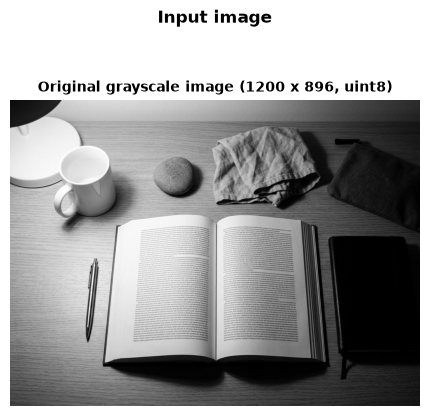

In [3]:
IMAGE_PATH = "input_image.jpg"
as_stored = cv2.imread(IMAGE_PATH, cv2.IMREAD_UNCHANGED)
original = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

if original is None or as_stored is None:
    raise FileNotFoundError(f"Could not read {IMAGE_PATH}; keep it beside this notebook")
assert original.ndim == 2, "working image must be single-channel grayscale"
assert original.dtype == np.uint8, "working image must be 8-bit"
assert as_stored.ndim == 3 and as_stored.shape[2] == 3, "stored JPG must have three channels"
assert min(original.shape) >= 300, "image must be at least 300 x 300 pixels"

original.setflags(write=False)
height, width = original.shape
channels = 1 if as_stored.ndim == 2 else as_stored.shape[2]
print("File                      :", IMAGE_PATH)
print("Stored channels / dtype   :", channels, "/", as_stored.dtype)
print("Shape (rows, cols)        :", original.shape)
print("dtype                     :", original.dtype)
print("Minimum intensity         :", int(original.min()))
print("Maximum intensity         :", int(original.max()))
print("Original is read-only     :", not original.flags.writeable)
print("Size >= 300 x 300:", min(original.shape) >= 300)
show_gray([original], [f"Original grayscale image ({width} x {height}, uint8)"],
          "Input image", "a_original")

12.23% of the pixels exceed 255 after +40; unsafe uint8 arithmetic turns them dark.
Unsafe and safe results identical? False


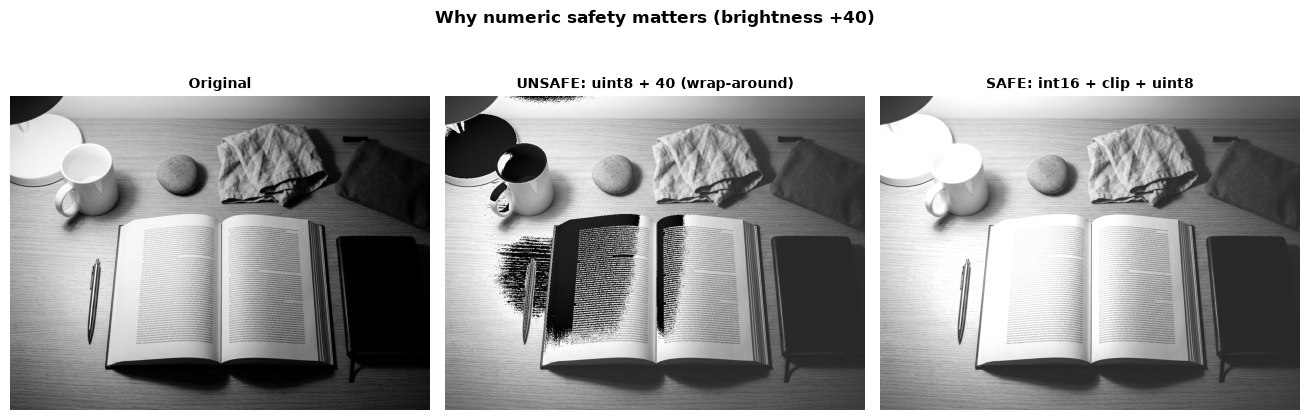

In [4]:
# The same +40 brightness shift on the real image, done unsafely and safely
unsafe_img = original + np.uint8(40)                          # uint8 arithmetic -> wrap-around
safe_img   = to_uint8(original.astype(np.int16) + 40)         # widen, clip, convert

wrapped_px = pct(original.astype(np.int16) + 40 > 255)
print(f"{wrapped_px:.2f}% of the pixels exceed 255 after +40; unsafe uint8 arithmetic turns them dark.")
print("Unsafe and safe results identical?", np.array_equal(unsafe_img, safe_img))

show_gray([original, unsafe_img, safe_img],
          ["Original", "UNSAFE: uint8 + 40 (wrap-around)", "SAFE: int16 + clip + uint8"],
          "Why numeric safety matters (brightness +40)", "a_numeric_safety")

---
## Operation 1 — Brightness adjustment

**Rule:** `s = r + β`, with `β = +40` and `β = −40`. Widen, clip, then convert to `uint8`.

### Dry run 1 — Hand calculation

Pixels: `[30, 80, 128, 180, 240]`

**Brightness +40**

| Input `r` | Raw `r + 40` | Clipped value | Final `uint8` |
|---:|---:|---:|---:|
| 30 | 70 | 70 | 70 |
| 80 | 120 | 120 | 120 |
| 128 | 168 | 168 | 168 |
| 180 | 220 | 220 | 220 |
| 240 | 280 | 255 | 255 |

**Brightness −40**

| Input `r` | Raw `r − 40` | Clipped value | Final `uint8` |
|---:|---:|---:|---:|
| 30 | −10 | 0 | 0 |
| 80 | 40 | 40 | 40 |
| 128 | 88 | 88 | 88 |
| 180 | 140 | 140 | 140 |
| 240 | 200 | 200 | 200 |

Clipping is irreversible: after the +40 result clips, subtracting 40 maps 240 back to 215. In the image, inputs above 215 clip to 255 and inputs below 40 clip to 0.

With +40, inputs 240 and 255 both become 255; every input at or above 215 merges at 255. With −40, input 30 clips to 0, merging with every input at or below 40. Clipping is irreversible: applying +40 then −40 returns 215 for input 240, not 240.


### Dry run 1 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [5]:
typed_pixels = [30, 80, 128, 180, 240]
typed_plus_raw = [70, 120, 168, 220, 280]
typed_plus_final = [70, 120, 168, 220, 255]
typed_minus_raw = [-10, 40, 88, 140, 200]
typed_minus_final = [0, 40, 88, 140, 200]
px = np.array(typed_pixels, dtype=np.uint8)
wide = px.astype(np.int16)
plus_raw, minus_raw = wide + 40, wide - 40
plus_final, minus_final = to_uint8(plus_raw), to_uint8(minus_raw)
show_table(["Input r", "Raw r + 40", "Clipped value", "Final uint8"],
           [[int(r), int(a), int(np.clip(a, 0, 255)), int(b)] for r,a,b in zip(px,plus_raw,plus_final)],
           "Python dry run 1 — brightness +40")
show_table(["Input r", "Raw r - 40", "Clipped value", "Final uint8"],
           [[int(r), int(a), int(np.clip(a, 0, 255)), int(b)] for r,a,b in zip(px,minus_raw,minus_final)],
           "Python dry run 1 — brightness -40")
assert plus_raw.tolist()==typed_plus_raw and plus_final.tolist()==typed_plus_final
assert minus_raw.tolist()==typed_minus_raw and minus_final.tolist()==typed_minus_final
undo_plus = to_uint8(plus_final.astype(np.int16)-40)
assert undo_plus.tolist()==[30,80,128,180,215]
print("✓ MATCH — both brightness tables match the hand calculation")

Python dry run 1 — brightness +40
+---------+------------+---------------+-------------+
| Input r | Raw r + 40 | Clipped value | Final uint8 |
+---------+------------+---------------+-------------+
|    30   |     70     |       70      |      70     |
|    80   |    120     |      120      |     120     |
|   128   |    168     |      168      |     168     |
|   180   |    220     |      220      |     220     |
|   240   |    280     |      255      |     255     |
+---------+------------+---------------+-------------+
Python dry run 1 — brightness -40
+---------+------------+---------------+-------------+
| Input r | Raw r - 40 | Clipped value | Final uint8 |
+---------+------------+---------------+-------------+
|    30   |    -10     |       0       |      0      |
|    80   |     40     |       40      |      40     |
|   128   |     88     |       88      |      88     |
|   180   |    140     |      140      |     140     |
|   240   |    200     |      200      |     200    

### Image task 1 — Brightness shifts and nested-loop check

Nested-loop +40 identical to NumPy +40: True
Run time: nested loops 1.98 s | NumPy 6.4 ms


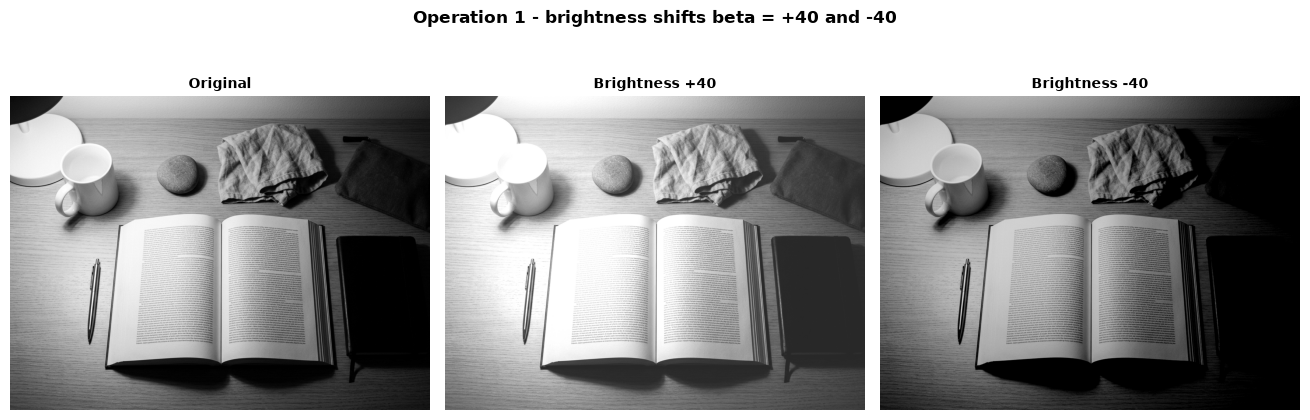

+----------------+--------+---------+-----+-----+--------+----------+
|     Image      |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+----------------+--------+---------+-----+-----+--------+----------+
|    Original    | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
| Brightness +40 | 156.13 |  76.20  |  40 | 255 |  0.00  |  12.64   |
| Brightness -40 | 85.16  |  70.25  |  0  | 215 | 25.16  |   0.00   |
+----------------+--------+---------+-----+-----+--------+----------+
Brightness clipping summary
+----------------+--------------------+
|   Operation    | Pixels clipped (%) |
+----------------+--------------------+
| Brightness +40 |       12.23%       |
| Brightness -40 |       24.84%       |
+----------------+--------------------+


In [6]:
beta = 40
wide_img = original.astype(np.int16)             # int16 holds -40 ... 295 without overflow
brighter = to_uint8(wide_img + beta)
darker   = to_uint8(wide_img - beta)

# +40 again, with explicit nested loops
t0 = time.perf_counter()
brighter_loops = np.empty_like(original)
for row in range(height):
    for col in range(width):
        value = int(original[row, col]) + beta           # Python int -> no uint8 wrap-around
        brighter_loops[row, col] = min(255, max(0, value))
loop_time = time.perf_counter() - t0

t0 = time.perf_counter()
_ = to_uint8(original.astype(np.int16) + beta)
numpy_time = time.perf_counter() - t0

same = np.array_equal(brighter, brighter_loops)
print("Nested-loop +40 identical to NumPy +40:", same)
assert same
print(f"Run time: nested loops {loop_time:.2f} s | NumPy {numpy_time * 1000:.1f} ms")

show_gray([original, brighter, darker],
          ["Original", "Brightness +40", "Brightness -40"],
          "Operation 1 - brightness shifts beta = +40 and -40", "op1_brightness")
show_stats([("Original", original), ("Brightness +40", brighter), ("Brightness -40", darker)])
clip_stats = [["Brightness +40", f"{pct(wide_img + beta > 255):.2f}%"],
              ["Brightness -40", f"{pct(wide_img - beta < 0):.2f}%"]]
show_table(["Operation", "Pixels clipped (%)"], clip_stats, "Brightness clipping summary")


### Observation and verification — Brightness adjustment

- Adding 40 raises the mean from **118.31** to **156.13**; **12.23%** of pixels clip at 255. Subtracting 40 lowers it to **85.16**; **24.84%** clip at 0, losing distinctions in those highlights and shadows.
- Standard deviation changes from **79.27** to **76.20** (+40) and **70.25** (−40). A uniform shift does not expand spread; here clipping compresses its extremes.
- **Verification:** nested-loop +40 is pixel-for-pixel identical to NumPy. The timing above shows the speed advantage of vectorization.


---
## Operation 2 — Linear contrast from zero

**Rule:** `s = αr + β`, with `α = 1.5` and `β = 0`. Use floating-point arithmetic, clip, then truncate.

### Dry run 2 — Hand calculation

Pixels: `[30, 80, 128, 180, 240]`

| Input `r` | Raw `1.5r` | Clipped value | Final `uint8` | Saturated? |
|---:|---:|---:|---:|:---:|
| 30 | 45 | 45 | 45 | No |
| 80 | 120 | 120 | 120 | No |
| 128 | 192 | 192 | 192 | No |
| 180 | 270 | 255 | 255 | Yes |
| 240 | 360 | 255 | 255 | Yes |

Inputs 180 and 240 both map to 255, so their difference is lost. Scaling from zero spreads levels and also raises the image mean.

### Dry run 2 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [7]:
typed_pixels = [30, 80, 128, 180, 240]
typed_raw = [45, 120, 192, 270, 360]
typed_final = [45, 120, 192, 255, 255]
px = np.array(typed_pixels, dtype=np.uint8)
alpha = 1.5
raw = alpha * px.astype(np.float64)
final = to_uint8(raw)
saturated = raw > 255
show_table(["Input r", "Raw 1.5r", "Clipped value", "Final uint8", "Saturated?"],
           [[int(r), float(v), float(np.clip(v,0,255)), int(o), bool(s)] for r,v,o,s in zip(px,raw,final,saturated)],
           "Python dry run 2 — linear contrast from zero")
assert np.allclose(raw,typed_raw) and final.tolist()==typed_final and saturated.tolist()==[False,False,False,True,True]
print("✓ MATCH — the Python table matches the hand calculation")

Python dry run 2 — linear contrast from zero
+---------+----------+---------------+-------------+------------+
| Input r | Raw 1.5r | Clipped value | Final uint8 | Saturated? |
+---------+----------+---------------+-------------+------------+
|    30   |   45.0   |      45.0     |      45     |   False    |
|    80   |  120.0   |     120.0     |     120     |   False    |
|   128   |  192.0   |     192.0     |     192     |   False    |
|   180   |  270.0   |     255.0     |     255     |    True    |
|   240   |  360.0   |     255.0     |     255     |    True    |
+---------+----------+---------------+-------------+------------+
✓ MATCH — the Python table matches the hand calculation


### Image task 2 — Linear contrast from zero

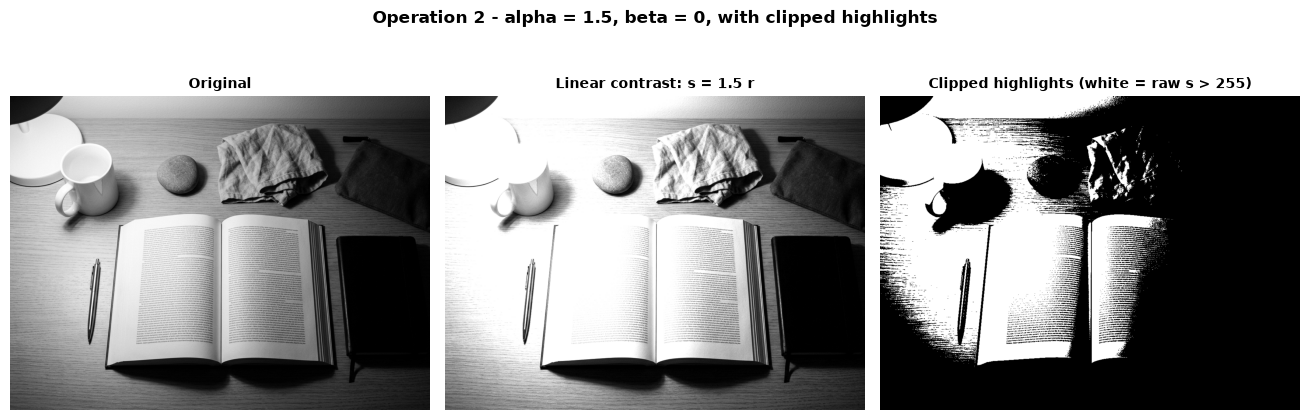

+-----------+--------+---------+-----+-----+--------+----------+
|   Image   |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+-----------+--------+---------+-----+-----+--------+----------+
|  Original | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
| s = 1.5 r | 158.78 |  97.53  |  0  | 255 |  5.02  |  33.86   |
+-----------+--------+---------+-----+-----+--------+----------+
Clipped highlight-mask share: 33.38%


In [8]:
alpha, beta0 = 1.5, 0.0
raw_zero = alpha * original.astype(np.float64) + beta0
contrast_zero = to_uint8(raw_zero)

clipped_highlights = np.where(raw_zero > 255, 255, 0).astype(np.uint8)
show_gray([original, contrast_zero, clipped_highlights],
          ["Original", "Linear contrast: s = 1.5 r", "Clipped highlights (white = raw s > 255)"],
          "Operation 2 - alpha = 1.5, beta = 0, with clipped highlights", "op2_linear_contrast", per_row=3)
show_stats([("Original", original), ("s = 1.5 r", contrast_zero)])

sat_zero = pct(raw_zero > 255)
assert np.array_equal(clipped_highlights, np.where(raw_zero > 255, 255, 0).astype(np.uint8))
print(f"Clipped highlight-mask share: {pct(clipped_highlights == 255):.2f}%")


### Observation and interpretation — Linear contrast from zero

- With `s = 1.5r`, mean rises from **118.31** to **158.78**: scaling from zero makes the image brighter as well as increasing its spread.
- The clipped-highlight mask marks **33.38%** of pixels: those raw values exceed 255 and become white. The share at 255 grows from **0.03%** to **33.86%**, while the share at 0 stays **5.02%**; highlight detail is lost.
- Standard deviation rises from **79.27** to **97.53**, confirming a larger spread after clipping.


---
## Operation 3 — Contrast centered at 128

**Rule:** `s = (r − 128)α + 128`, with `α = 1.5` and `α = 0.5`.

### Dry run 3 — Hand calculation

Pixels: `[30, 80, 128, 180, 240]`

**Contrast expansion, `α = 1.5`**

| `r` | `r − 128` | `(r − 128) × 1.5` | Raw output | Clipped / final `uint8` |
|---:|---:|---:|---:|---:|
| 30 | −98 | −147 | −19 | 0 |
| 80 | −48 | −72 | 56 | 56 |
| 128 | 0 | 0 | 128 | 128 |
| 180 | 52 | 78 | 206 | 206 |
| 240 | 112 | 168 | 296 | 255 |

**Contrast compression, `α = 0.5`**

| `r` | `r − 128` | `(r − 128) × 0.5` | Raw output | Clipped / final `uint8` |
|---:|---:|---:|---:|---:|
| 30 | −98 | −49 | 79 | 79 |
| 80 | −48 | −24 | 104 | 104 |
| 128 | 0 | 0 | 128 | 128 |
| 180 | 52 | 26 | 154 | 154 |
| 240 | 112 | 56 | 184 | 184 |

At `r = 128`, `(128 − 128) = 0` and `0 × α = 0` for any `α`, so the output is 128 again: the pivot is a fixed point. Contrast from zero in Dry run 2 maps 128 to 192. `α > 1` expands distances from the pivot and can clip extremes; `α < 1` compresses distances toward it.

### Dry run 3 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [9]:
typed_pixels = [30, 80, 128, 180, 240]
px = np.array(typed_pixels, dtype=np.uint8)
typed_raw_15 = [-19,56,128,206,296]
typed_final_15 = [0,56,128,206,255]
typed_raw_05 = [79,104,128,154,184]
typed_final_05 = [79,104,128,154,184]
def centred_raw(values,a): return (np.asarray(values,dtype=np.float64)-128.0)*a+128.0
raw_15, raw_05 = centred_raw(px,1.5), centred_raw(px,0.5)
final_15, final_05 = to_uint8(raw_15), to_uint8(raw_05)
show_table(["Input r","r - 128","(r - 128) x 1.5","Raw output","Clipped / final uint8"],
           [[int(r),int(r)-128,float((int(r)-128)*1.5),float(v),int(o)] for r,v,o in zip(px,raw_15,final_15)],
           "Python dry run 3 — centered contrast, alpha = 1.5")
show_table(["Input r","r - 128","(r - 128) x 0.5","Raw output","Clipped / final uint8"],
           [[int(r),int(r)-128,float((int(r)-128)*0.5),float(v),int(o)] for r,v,o in zip(px,raw_05,final_05)],
           "Python dry run 3 — centered contrast, alpha = 0.5")
assert np.allclose(raw_15,typed_raw_15) and final_15.tolist()==typed_final_15
assert np.allclose(raw_05,typed_raw_05) and final_05.tolist()==typed_final_05
print("✓ MATCH — both centered-contrast tables match the hand calculation; r = 128 stays fixed")

Python dry run 3 — centered contrast, alpha = 1.5
+---------+---------+-----------------+------------+-----------------------+
| Input r | r - 128 | (r - 128) x 1.5 | Raw output | Clipped / final uint8 |
+---------+---------+-----------------+------------+-----------------------+
|    30   |   -98   |      -147.0     |   -19.0    |           0           |
|    80   |   -48   |      -72.0      |    56.0    |           56          |
|   128   |    0    |       0.0       |   128.0    |          128          |
|   180   |    52   |       78.0      |   206.0    |          206          |
|   240   |   112   |      168.0      |   296.0    |          255          |
+---------+---------+-----------------+------------+-----------------------+
Python dry run 3 — centered contrast, alpha = 0.5
+---------+---------+-----------------+------------+-----------------------+
| Input r | r - 128 | (r - 128) x 0.5 | Raw output | Clipped / final uint8 |
+---------+---------+-----------------+------------+-

### Image task 3 — Centered contrast versus contrast from zero

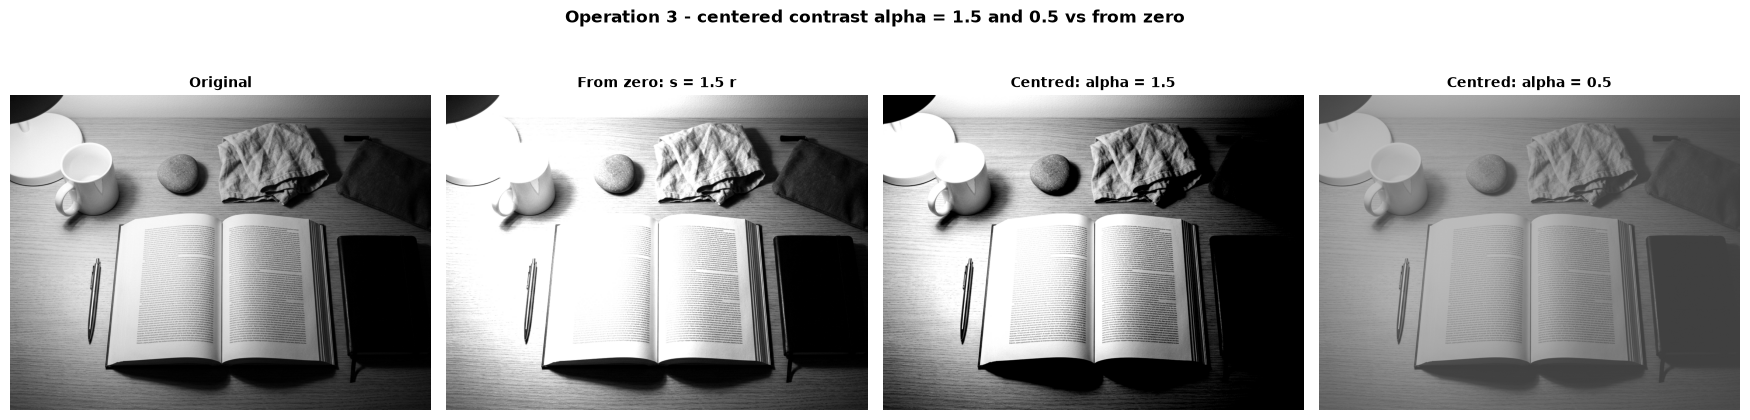

+---------------+--------+---------+-----+-----+--------+----------+
|     Image     |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+---------------+--------+---------+-----+-----+--------+----------+
|    Original   | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
| From zero 1.5 | 158.78 |  97.53  |  0  | 255 |  5.02  |  33.86   |
|  Centred 1.5  | 120.89 |  98.58  |  0  | 255 | 26.09  |  13.42   |
|  Centred 0.5  | 122.91 |  39.62  |  64 | 191 |  0.00  |   0.00   |
+---------------+--------+---------+-----+-----+--------+----------+
Centered contrast clipping and floor occupancy
+--------------------------------+------------+
|            Measure             | Percentage |
+--------------------------------+------------+
|  Raw alpha=1.5 values below 0  |   25.79%   |
| Raw alpha=1.5 values above 255 |   13.42%   |
|  Final alpha=1.5 pixels at 0   |   26.09%   |
+--------------------------------+------------+
Operation 3 — mean shifts compared with the original
+-----------

In [10]:
raw_c15 = centred_raw(original, 1.5)
raw_c05 = centred_raw(original, 0.5)
centred_15 = to_uint8(raw_c15)
centred_05 = to_uint8(raw_c05)

show_gray([original, contrast_zero, centred_15, centred_05],
          ["Original", "From zero: s = 1.5 r", "Centred: alpha = 1.5", "Centred: alpha = 0.5"],
          "Operation 3 - centered contrast alpha = 1.5 and 0.5 vs from zero", "op3_centred_contrast",
          per_row=4)
show_stats([("Original", original), ("From zero 1.5", contrast_zero),
             ("Centred 1.5", centred_15), ("Centred 0.5", centred_05)])
show_table(["Measure", "Percentage"],
           [["Raw alpha=1.5 values below 0", f"{pct(raw_c15 < 0):.2f}%"],
            ["Raw alpha=1.5 values above 255", f"{pct(raw_c15 > 255):.2f}%"],
            ["Final alpha=1.5 pixels at 0", f"{pct(centred_15 == 0):.2f}%"]],
           "Centered contrast clipping and floor occupancy")
mean_shift_zero = contrast_zero.mean() - original.mean()
mean_shift_center = centred_15.mean() - original.mean()
show_table(["Contrast method", "Mean shift"],
           [["Alpha = 1.5 from zero", f"{mean_shift_zero:+.2f}"],
            ["Alpha = 1.5 centered at 128", f"{mean_shift_center:+.2f}"]],
           "Operation 3 — mean shifts compared with the original")


### Observation and interpretation — Contrast centered at 128

- At `α = 1.5`, standard deviation rises from **79.27** to **98.58**, while the mean changes only from **118.31** to **120.89**. Raw values below 0 account for **25.79%** and above 255 for **13.42%**; the final share at 0 is **26.09%**.
- Centered contrast changes the mean by **+2.58**, versus **+40.47** for `1.5r`; 128 remains the fixed pivot.
- At `α = 0.5`, range contracts to **64–191** and standard deviation falls to **39.62**, producing a flatter result without clipping.


---
## Operation 4 — Image negative

**Rule:** `s = 255 − r`.

### Dry run 4 — Hand calculation

Pixels: `[30, 80, 128, 180, 240]`

**First negative**

| Input `r` | `255 − r` |
|---:|---:|
| 30 | 225 |
| 80 | 175 |
| 128 | 127 |
| 180 | 75 |
| 240 | 15 |

**Apply the negative a second time**

| Negative value | `255 − negative` | Recovered input | Equals original? |
|---:|---:|---:|:---:|
| 225 | 30 | 30 | Yes |
| 175 | 80 | 80 | Yes |
| 127 | 128 | 128 | Yes |
| 75 | 180 | 180 | Yes |
| 15 | 240 | 240 | Yes |

Applying the transform twice recovers each input. A negative can help inspect faint bright structures in dark images, such as details in an X-ray.

### Dry run 4 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [11]:
typed_pixels = [30, 80, 128, 180, 240]
typed_negative = [225, 175, 127, 75, 15]
typed_restored = [30, 80, 128, 180, 240]
px = np.array(typed_pixels, dtype=np.uint8)
neg = to_uint8(255-px.astype(np.int16))
back = to_uint8(255-neg.astype(np.int16))
show_table(["Input r","255 - r"],[[int(r),int(v)] for r,v in zip(px,neg)],"Python dry run 4 — first negative")
show_table(["Negative value","255 - negative","Recovered input","Equals original?"],[[int(v),int(z),int(r),"Yes" if z==r else "No"] for r,v,z in zip(px,neg,back)],"Python dry run 4 — apply negative again")
assert neg.tolist()==typed_negative and back.tolist()==typed_restored and back.tolist()==px.tolist()
print("✓ MATCH — both negative tables match the hand calculation")

Python dry run 4 — first negative
+---------+---------+
| Input r | 255 - r |
+---------+---------+
|    30   |   225   |
|    80   |   175   |
|   128   |   127   |
|   180   |    75   |
|   240   |    15   |
+---------+---------+
Python dry run 4 — apply negative again
+----------------+----------------+-----------------+------------------+
| Negative value | 255 - negative | Recovered input | Equals original? |
+----------------+----------------+-----------------+------------------+
|      225       |       30       |        30       |       Yes        |
|      175       |       80       |        80       |       Yes        |
|      127       |      128       |       128       |       Yes        |
|       75       |      180       |       180       |       Yes        |
|       15       |      240       |       240       |       Yes        |
+----------------+----------------+-----------------+------------------+
✓ MATCH — both negative tables match the hand calculation


### Image task 4 — Image negative

Negative applied twice is identical to the original image: True


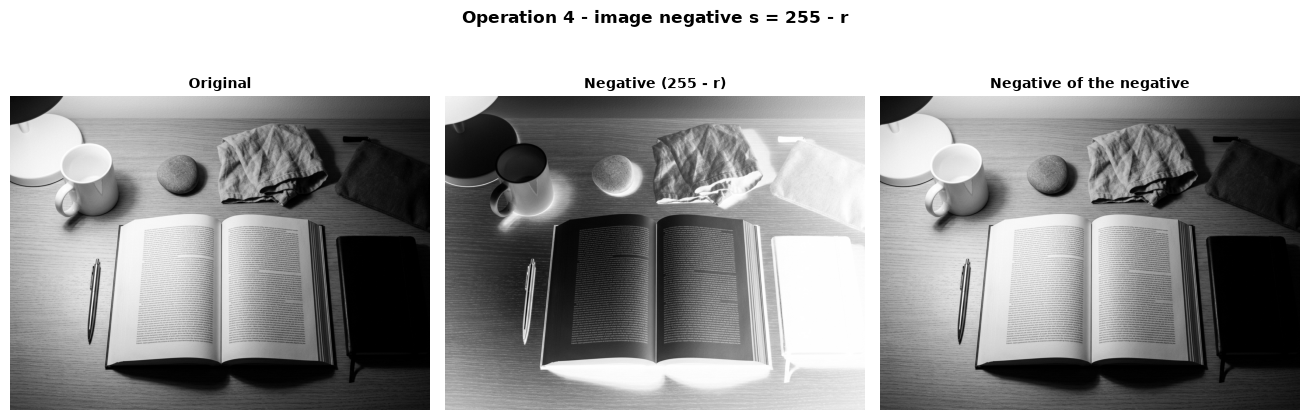

+----------+--------+---------+-----+-----+--------+----------+
|  Image   |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+----------+--------+---------+-----+-----+--------+----------+
| Original | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
| Negative | 136.69 |  79.27  |  0  | 255 |  0.03  |   5.02   |
+----------+--------+---------+-----+-----+--------+----------+


In [12]:
negative      = to_uint8(255 - original.astype(np.int16))
neg_of_neg    = to_uint8(255 - negative.astype(np.int16))

assert np.array_equal(neg_of_neg, original)
print("Negative applied twice is identical to the original image: True")

show_gray([original, negative, neg_of_neg],
          ["Original", "Negative (255 - r)", "Negative of the negative"],
          "Operation 4 - image negative s = 255 - r", "op4_negative")
show_stats([("Original", original), ("Negative", negative)])


### Observation and verification — Image negative

- `255 − r` swaps dark and bright levels. Mean changes from **118.31** to **136.69**, while standard deviation remains **79.27** because intensity distances are preserved.
- **Verification:** applying the negative twice reproduces the original pixel-for-pixel; the assertion above checks this.
- A negative may help inspect a small bright feature against a large dark background, such as in a radiograph.


---
## Operation 5 — Gamma correction

**Rule used:** `s = 255(r/255)^γ`, with `γ = 0.5` and `γ = 2.0`. Keep full precision through normalization, exponentiation, and scaling; truncate only the final result.

### Dry run 5 — Hand calculation

Pixels: `[0, 64, 128, 192, 255]`

**Gamma `γ = 0.5`**

| `r` | `r/255` | `(r/255)^0.5` | Scaled value | Final `uint8` |
|---:|---:|---:|---:|---:|
| 0 | 0.000000 | 0.000000 | 0.0000 | 0 |
| 64 | 0.250980 | 0.500979 | 127.7498 | 127 |
| 128 | 0.501961 | 0.708492 | 180.6654 | 180 |
| 192 | 0.752941 | 0.867722 | 221.2691 | 221 |
| 255 | 1.000000 | 1.000000 | 255.0000 | 255 |

**Gamma `γ = 2.0`**

| `r` | `r/255` | `(r/255)^2` | Scaled value | Final `uint8` |
|---:|---:|---:|---:|---:|
| 0 | 0.000000 | 0.000000 | 0.0000 | 0 |
| 64 | 0.250980 | 0.062991 | 16.0627 | 16 |
| 128 | 0.501961 | 0.251965 | 64.2510 | 64 |
| 192 | 0.752941 | 0.566920 | 144.5647 | 144 |
| 255 | 1.000000 | 1.000000 | 255.0000 | 255 |

Under this convention, `γ < 1` brightens dark and mid tones, while `γ > 1` darkens them. Both endpoints, 0 and 255, stay fixed.

### Dry run 5 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [13]:
typed_gamma_pixels = [0, 64, 128, 192, 255]
typed_gamma_half = [0, 127, 180, 221, 255]
typed_gamma_two = [0, 16, 64, 144, 255]
gpx=np.array(typed_gamma_pixels,dtype=np.uint8)
def gamma_scaled(values,g): return 255.0*(np.asarray(values,dtype=np.float64)/255.0)**g
norm=gpx.astype(np.float64)/255.0
outputs={}
for g in (0.5,2.0):
    power=norm**g; scaled=255.0*power; final=to_uint8(scaled); outputs[g]=(scaled,final)
    show_table(["r","r / 255",f"(r / 255)^{g}","Scaled value","Final uint8"],
               [[int(r),f"{x:.6f}",f"{y:.6f}",f"{z:.4f}",int(o)] for r,x,y,z,o in zip(gpx,norm,power,scaled,final)],
               f"Python dry run 5 — gamma = {g}")
assert outputs[0.5][1].tolist()==typed_gamma_half
assert outputs[2.0][1].tolist()==typed_gamma_two
assert np.allclose(outputs[0.5][0],[0,127.7498,180.6654,221.2691,255],atol=5e-5)
assert np.allclose(outputs[2.0][0],[0,16.0627,64.2510,144.5647,255],atol=5e-5)
print("✓ MATCH — both gamma tables match the hand calculation; 0 and 255 stay fixed")

Python dry run 5 — gamma = 0.5
+-----+----------+---------------+--------------+-------------+
|  r  | r / 255  | (r / 255)^0.5 | Scaled value | Final uint8 |
+-----+----------+---------------+--------------+-------------+
|  0  | 0.000000 |    0.000000   |    0.0000    |      0      |
|  64 | 0.250980 |    0.500979   |   127.7498   |     127     |
| 128 | 0.501961 |    0.708492   |   180.6654   |     180     |
| 192 | 0.752941 |    0.867722   |   221.2691   |     221     |
| 255 | 1.000000 |    1.000000   |   255.0000   |     255     |
+-----+----------+---------------+--------------+-------------+
Python dry run 5 — gamma = 2.0
+-----+----------+---------------+--------------+-------------+
|  r  | r / 255  | (r / 255)^2.0 | Scaled value | Final uint8 |
+-----+----------+---------------+--------------+-------------+
|  0  | 0.000000 |    0.000000   |    0.0000    |      0      |
|  64 | 0.250980 |    0.062991   |   16.0627    |      16     |
| 128 | 0.501961 |    0.251965   |   64.25

In [14]:
# Compare the lab rule (full precision, truncate final value) with nearest-integer rounding.
rows = []
rounded_typed = {0.5: [0, 128, 181, 221, 255], 2.0: [0, 16, 64, 145, 255]}
for gamma_value in (0.5, 2.0):
    scaled = gamma_scaled(gpx, gamma_value)
    truncated = to_uint8(scaled)
    rounded = round_half_up(scaled).astype(np.uint8)
    assert rounded.tolist() == rounded_typed[gamma_value]
    for r, exact, trunc_value, round_value in zip(gpx, scaled, truncated, rounded):
        rows.append([gamma_value, int(r), f"{exact:.4f}", int(trunc_value), int(round_value)])
show_table(["gamma", "r", "Full-precision scaled value", "Truncated (lab)", "Rounded"], rows,
           "Dry run 5 — full-precision truncation versus rounding")

Dry run 5 — full-precision truncation versus rounding
+-------+-----+-----------------------------+-----------------+---------+
| gamma |  r  | Full-precision scaled value | Truncated (lab) | Rounded |
+-------+-----+-----------------------------+-----------------+---------+
|  0.5  |  0  |            0.0000           |        0        |    0    |
|  0.5  |  64 |           127.7498          |       127       |   128   |
|  0.5  | 128 |           180.6654          |       180       |   181   |
|  0.5  | 192 |           221.2691          |       221       |   221   |
|  0.5  | 255 |           255.0000          |       255       |   255   |
|  2.0  |  0  |            0.0000           |        0        |    0    |
|  2.0  |  64 |           16.0627           |        16       |    16   |
|  2.0  | 128 |           64.2510           |        64       |    64   |
|  2.0  | 192 |           144.5647          |       144       |   145   |
|  2.0  | 255 |           255.0000          |       255   

**Why the slide-style value can differ.** For this comparison, the slide example is treated as nearest-integer rounding of the full-precision scaled value, while the lab truncates only the final value. Thus `127.7498` at `r = 64`, `γ = 0.5` rounds to **128** but truncates to **127** here; `180.6654` at `r = 128` rounds to **181** but truncates to **180** here. The comparison table above computes both rules for both gamma values.


### Image task 5 — Gamma correction

Ramp check: 0 -> 0 and 255 -> 255 for gamma = 0.5 and gamma = 2.0
Image check: the 53948 pixels equal to 0 and the 321 pixels equal to 255 are unchanged by both gamma values.


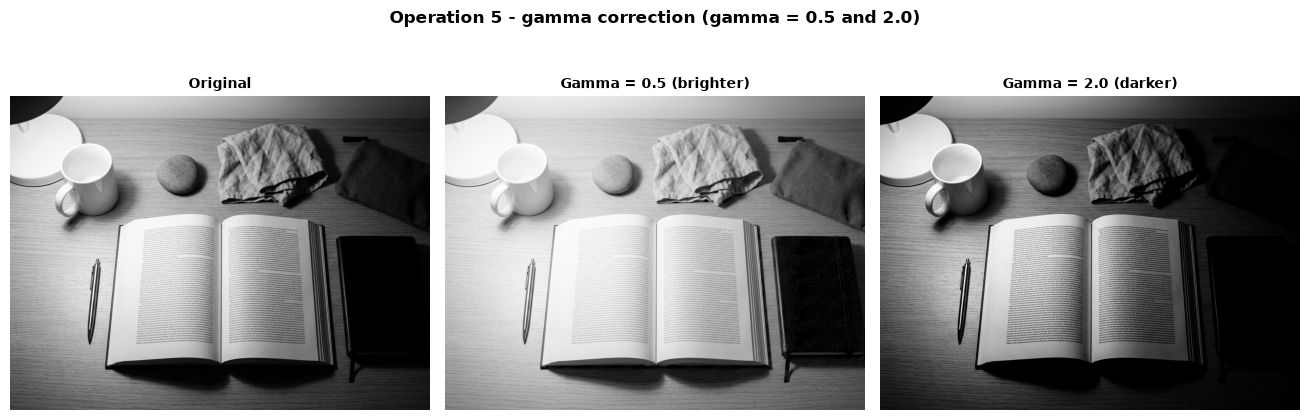

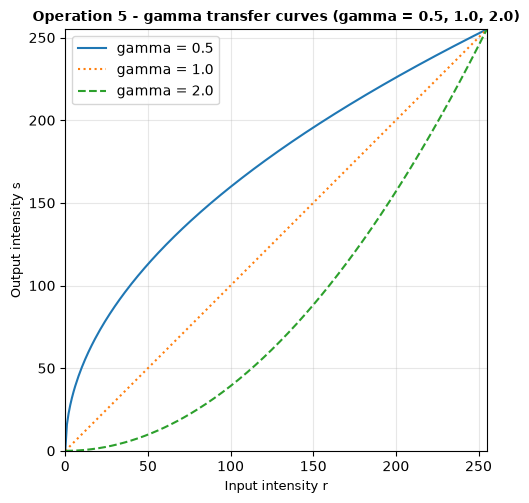

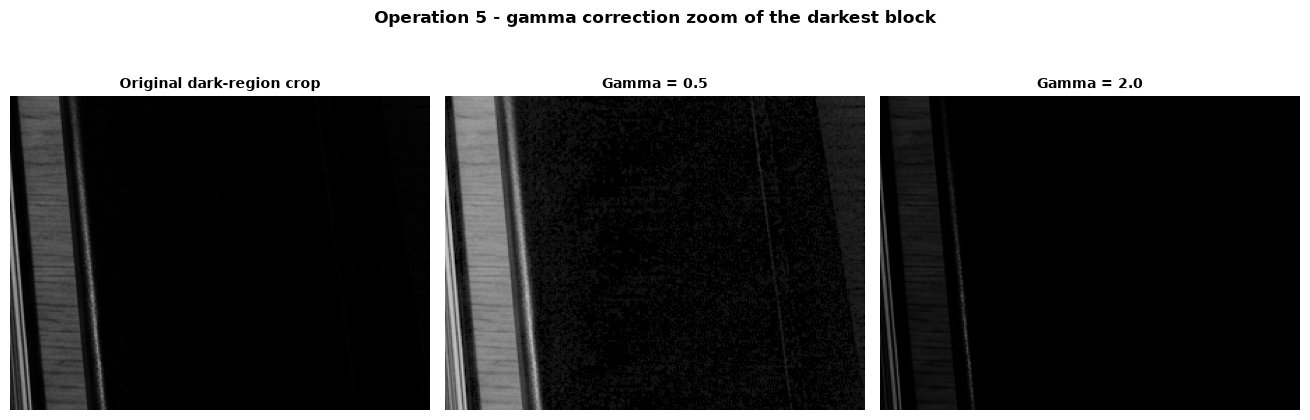

Gamma response in the darkest 25% of pixels
+-----------------------+----------------+---------------+----------------+----------------+
|         Region        | Share of image | Original mean | Gamma 0.5 mean | Gamma 2.0 mean |
+-----------------------+----------------+---------------+----------------+----------------+
| Darkest 25% (r <= 40) |     25.16%     |     12.77     |     45.25      |      1.04      |
+-----------------------+----------------+---------------+----------------+----------------+
+-----------+--------+---------+-----+-----+--------+----------+
|   Image   |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+-----------+--------+---------+-----+-----+--------+----------+
|  Original | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
| Gamma 0.5 | 156.11 |  75.02  |  0  | 255 |  5.02  |   0.03   |
| Gamma 2.0 | 79.14  |  73.90  |  0  | 255 | 15.52  |   0.03   |
+-----------+--------+---------+-----+-----+--------+----------+


In [15]:
dark_cut = int(np.percentile(original, 25))
dark_zone = original <= dark_cut
gamma_half = to_uint8(gamma_scaled(original, 0.5))
gamma_two  = to_uint8(gamma_scaled(original, 2.0))

# fixed points: check on the complete 0..255 ramp and on the image itself
ramp = np.arange(256, dtype=np.uint8)
for g in (0.5, 2.0):
    mapped = to_uint8(gamma_scaled(ramp, g))
    assert mapped[0] == 0 and mapped[255] == 255, "0 and 255 must stay fixed"
print("Ramp check: 0 -> 0 and 255 -> 255 for gamma = 0.5 and gamma = 2.0")
for g, out in ((0.5, gamma_half), (2.0, gamma_two)):
    assert np.all(out[original == 0] == 0) and np.all(out[original == 255] == 255)
print(f"Image check: the {int(np.sum(original == 0))} pixels equal to 0 and the {int(np.sum(original == 255))} pixels equal to 255 "
      f"are unchanged by both gamma values.")

show_gray([original, gamma_half, gamma_two],
          ["Original", "Gamma = 0.5 (brighter)", "Gamma = 2.0 (darker)"],
          "Operation 5 - gamma correction (gamma = 0.5 and 2.0)", "op5_gamma_images", per_row=3)

curve_x = np.arange(256)
fig, ax = plt.subplots(figsize=(7.2, 5.4))
for g, style in ((0.5, "-"), (1.0, ":"), (2.0, "--")):
    ax.plot(curve_x, gamma_scaled(curve_x, g), style, label=f"gamma = {g}")
ax.set_xlim(0, 255); ax.set_ylim(0, 255); ax.set_aspect("equal")
ax.set_title("Operation 5 - gamma transfer curves (gamma = 0.5, 1.0, 2.0)")
ax.set_xlabel("Input intensity r"); ax.set_ylabel("Output intensity s")
ax.legend(); ax.grid(alpha=0.3)
finish_figure(fig, "op5_gamma_curves")

dark_block, _ = extreme_blocks(original, 4)
dark_slice = block_slice(original.shape, dark_block[0], dark_block[1], 4)
show_gray([original[dark_slice], gamma_half[dark_slice], gamma_two[dark_slice]],
          ["Original dark-region crop", "Gamma = 0.5", "Gamma = 2.0"],
          "Operation 5 - gamma correction zoom of the darkest block", "op5_gamma_dark_zoom", per_row=3)
dark_share = pct(dark_zone)
show_table(["Region", "Share of image", "Original mean", "Gamma 0.5 mean", "Gamma 2.0 mean"],
           [[f"Darkest 25% (r <= {dark_cut})", f"{dark_share:.2f}%",
             f"{original[dark_zone].mean():.2f}", f"{gamma_half[dark_zone].mean():.2f}",
             f"{gamma_two[dark_zone].mean():.2f}"]],
           "Gamma response in the darkest 25% of pixels")
show_stats([("Original", original), ("Gamma 0.5", gamma_half), ("Gamma 2.0", gamma_two)])

### Observation and interpretation — Gamma correction

- The darkest quarter is defined here as `r ≤ 40`, which covers **25.16%** of the image. Its mean rises from **12.77** to **45.25** with `γ = 0.5`, while `γ = 2.0` lowers it to **1.04**.
- Across the full image, the means are **118.31** (original), **156.11** (`γ = 0.5`), and **79.14** (`γ = 2.0`). The separate curve and dark-region crop show the nonlinear brightening/darkening behavior.
- **Verification:** the full 0–255 ramp and endpoint-valued image pixels confirm that both mappings keep 0 and 255 fixed.


---
## Operation 6 — Grayscale histogram

### Dry run 6 — Hand calculation

Array: `A = [[0, 50, 50, 100], [100, 150, 200, 255]]`; total pixels: **8**.

| Intensity | Frequency | Probability `frequency / 8` |
|---:|---:|---:|
| 0 | 1 | 0.125 |
| 50 | 2 | 0.250 |
| 100 | 2 | 0.250 |
| 150 | 1 | 0.125 |
| 200 | 1 | 0.125 |
| 255 | 1 | 0.125 |
| **Total** | **8** | **1.000** |

A histogram counts how many pixels have each intensity; it does not retain their locations. Rearranging these values leaves the histogram unchanged.

### Dry run 6 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [16]:
typed_levels = [0, 50, 100, 150, 200, 255]
typed_frequencies = [1, 2, 2, 1, 1, 1]
typed_probabilities = [.125, .25, .25, .125, .125, .125]
A=np.array([[0,50,50,100],[100,150,200,255]],dtype=np.uint8)
levels,freq=np.unique(A,return_counts=True); prob=freq/A.size
rows=[[int(v),int(f),f"{q:.3f}"] for v,f,q in zip(levels,freq,prob)]
show_table(["Intensity","Frequency","Probability"],rows,"Python dry run 6 — histogram")
assert levels.tolist()==typed_levels
assert freq.tolist()==typed_frequencies and np.allclose(prob,typed_probabilities)
assert int(A.size)==8 and np.isclose(prob.sum(),1)
rearranged=np.flip(A)
assert np.array_equal(counts256(A),counts256(rearranged)) and not np.array_equal(A,rearranged)
print("✓ MATCH — frequencies, probabilities, and total count match the hand table")
print("✓ MATCH — rearranging pixels preserves the histogram")

Python dry run 6 — histogram
+-----------+-----------+-------------+
| Intensity | Frequency | Probability |
+-----------+-----------+-------------+
|     0     |     1     |    0.125    |
|     50    |     2     |    0.250    |
|    100    |     2     |    0.250    |
|    150    |     1     |    0.125    |
|    200    |     1     |    0.125    |
|    255    |     1     |    0.125    |
+-----------+-----------+-------------+
✓ MATCH — frequencies, probabilities, and total count match the hand table
✓ MATCH — rearranging pixels preserves the histogram


### Image task 6 — Original grayscale histogram

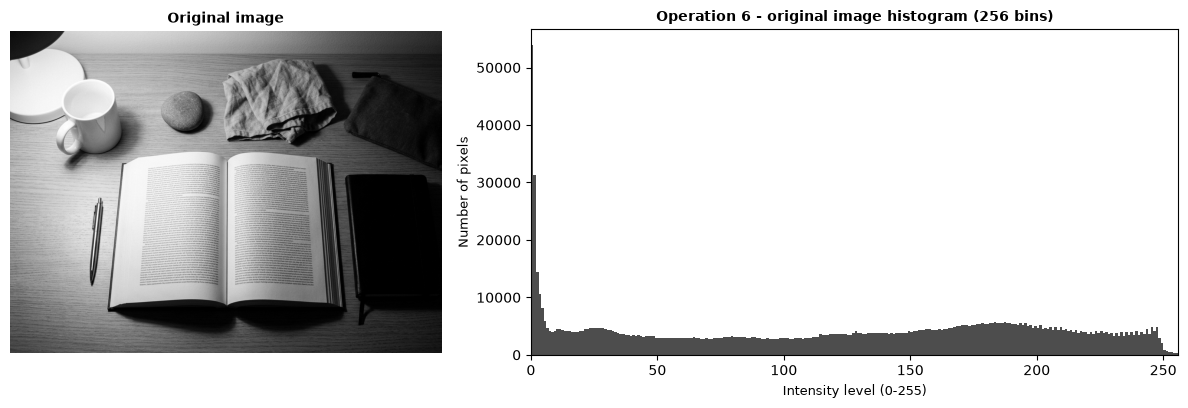

Operation 6 — intensity distribution measurements
+---------------------+----------------+
|      Statistic      | Measured value |
+---------------------+----------------+
|     Total pixels    |    1075200     |
|         Mean        |     118.3      |
|        Median       |      127       |
|  Standard deviation |      79.3      |
|       Below 85      |     37.5%      |
|    85 through 170   |     29.1%      |
|      Above 170      |     33.4%      |
|    5th percentile   |       0        |
|   95th percentile   |      236       |
| Most frequent level |       0        |
|         At 0        |     5.02%      |
|        At 255       |     0.03%      |
+---------------------+----------------+


In [17]:
hist_cv = cv2.calcHist([original], [0], None, [256], [0, 256]).ravel()
assert np.array_equal(hist_cv.astype(np.int64), counts256(original)), "OpenCV and NumPy histograms differ"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original image")
axes[0].axis("off")
draw_histogram(axes[1], original, "Operation 6 - original image histogram (256 bins)")
finish_figure(fig, "op6_histogram")

# --- two-sentence interpretation, written from the measured numbers ---
total   = original.size
mean_v, median_v = original.mean(), np.median(original)
p5, p95 = np.percentile(original, [5, 95])
peak    = int(np.argmax(counts256(original)))
tone    = "dark" if mean_v < 85 else ("bright" if mean_v > 170 else "mid-tone")
contrast = "low" if p95 - p5 < 100 else ("moderate" if p95 - p5 < 170 else "high")
share_dark = pct(original < 85)
share_middle = pct((original >= 85) & (original <= 170))
share_bright = pct(original > 170)
show_table(["Statistic", "Measured value"],
           [["Total pixels", f"{total}"], ["Mean", f"{mean_v:.1f}"], ["Median", f"{median_v:.0f}"], ["Standard deviation", f"{original.std():.1f}"],
            ["Below 85", f"{share_dark:.1f}%"], ["85 through 170", f"{share_middle:.1f}%"],
            ["Above 170", f"{share_bright:.1f}%"], ["5th percentile", f"{p5:.0f}"],
            ["95th percentile", f"{p95:.0f}"], ["Most frequent level", f"{peak}"],
            ["At 0", f"{pct(original == 0):.2f}%"], ["At 255", f"{pct(original == 255):.2f}%"]],
           "Operation 6 — intensity distribution measurements")


### Observation and interpretation — Grayscale histogram

Most pixels are mid-tone to bright: the mean is **118.3**, median **127**, and **29.1%** fall from 85 through 170, while **37.5%** are below 85 and **33.4%** above 170; the tallest bin is level **0**. The central 90% spans **0–236** (5th–95th percentiles; standard deviation **79.3**), with **5.02%** of pixels at 0 and **0.03%** at 255.


---
## Operation 7 — Global histogram equalization

### Dry run 7 — Hand calculation

Pixels: `[50, 50, 100, 150]`; total pixels: **4**.

**Histogram and cumulative distribution**

| Intensity | Frequency | Cumulative count | CDF |
|---:|---:|---:|---:|
| 50 | 2 | 2 | 0.50 |
| 100 | 1 | 3 | 0.75 |
| 150 | 1 | 4 | 1.00 |

**Mapping 1: `round_half_up(255 × CDF)`**

| Input level | `255 × CDF` | Rounded output |
|---:|---:|---:|
| 50 | 127.50 | 128 |
| 100 | 191.25 | 191 |
| 150 | 255.00 | 255 |

Output list: **[128, 128, 191, 255]**.

**Mapping 2: `round_half_up(255 × (CDF − CDFmin)/(1 − CDFmin))`**, where `CDFmin = 0.50`.

| Input level | Normalized value | Scaled value | Rounded output |
|---:|---:|---:|---:|
| 50 | 0.00 | 0.00 | 0 |
| 100 | 0.50 | 127.50 | 128 |
| 150 | 1.00 | 255.00 | 255 |

Output list: **[0, 0, 128, 255]**. This second mapping matches OpenCV’s result for these pixels; the first mapping does not use the full range.

### Dry run 7 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [18]:
typed_equalization_pixels = [50, 50, 100, 150]
typed_equalization_levels = [50, 100, 150]
typed_equalization_frequencies = [2, 1, 1]
typed_equalization_cumulative = [2, 3, 4]
typed_equalization_cdf = [.5, .75, 1.0]
typed_mapping1 = [128, 128, 191, 255]
typed_mapping2 = [0, 0, 128, 255]
eq_px=np.array(typed_equalization_pixels,dtype=np.uint8)
counts=counts256(eq_px); levels7=np.flatnonzero(counts); freq7=counts[levels7]
cum7=np.cumsum(counts)[levels7]; cdf7=cum7/eq_px.size; cdf_floor=cdf7[cdf7>0].min()
map1=round_half_up(255*cdf7); map2=round_half_up(255*(cdf7-cdf_floor)/(1-cdf_floor))
lookup1,lookup2=dict(zip(levels7,map1)),dict(zip(levels7,map2))
out1=[int(lookup1[v]) for v in eq_px]; out2=[int(lookup2[v]) for v in eq_px]
out_cv=cv2.equalizeHist(eq_px.reshape(1,-1)).ravel()
show_table(["Intensity","Frequency","Cumulative count","CDF"],
           [[int(l),int(f),int(c),f"{d:.2f}"] for l,f,c,d in zip(levels7,freq7,cum7,cdf7)],
           "Python dry run 7 — histogram and CDF")
show_table(["Input level","255 x CDF","Rounded output"],
           [[int(l),f"{255*d:.2f}",int(v)] for l,d,v in zip(levels7,cdf7,map1)],
           "Python dry run 7 — mapping 1")
show_table(["Input level","Normalized value","Scaled value","Rounded output"],
           [[int(l),f"{(d-cdf_floor)/(1-cdf_floor):.2f}",f"{255*(d-cdf_floor)/(1-cdf_floor):.2f}",int(v)] for l,d,v in zip(levels7,cdf7,map2)],
           "Python dry run 7 — mapping 2")
assert freq7.tolist()==typed_equalization_frequencies and cum7.tolist()==typed_equalization_cumulative and levels7.tolist()==typed_equalization_levels and np.allclose(cdf7,typed_equalization_cdf)
assert out1==typed_mapping1 and out2==typed_mapping2 and np.array_equal(out_cv,[0,0,128,255])
print("✓ MATCH — all dry-run tables match the hand calculation")
print("✓ MATCH — mapping 2 agrees with cv2.equalizeHist:",out_cv.tolist())

Python dry run 7 — histogram and CDF
+-----------+-----------+------------------+------+
| Intensity | Frequency | Cumulative count | CDF  |
+-----------+-----------+------------------+------+
|     50    |     2     |        2         | 0.50 |
|    100    |     1     |        3         | 0.75 |
|    150    |     1     |        4         | 1.00 |
+-----------+-----------+------------------+------+
Python dry run 7 — mapping 1
+-------------+-----------+----------------+
| Input level | 255 x CDF | Rounded output |
+-------------+-----------+----------------+
|      50     |   127.50  |      128       |
|     100     |   191.25  |      191       |
|     150     |   255.00  |      255       |
+-------------+-----------+----------------+
Python dry run 7 — mapping 2
+-------------+------------------+--------------+----------------+
| Input level | Normalized value | Scaled value | Rounded output |
+-------------+------------------+--------------+----------------+
|      50     |       0.0

### Image task 7 — Global histogram equalization

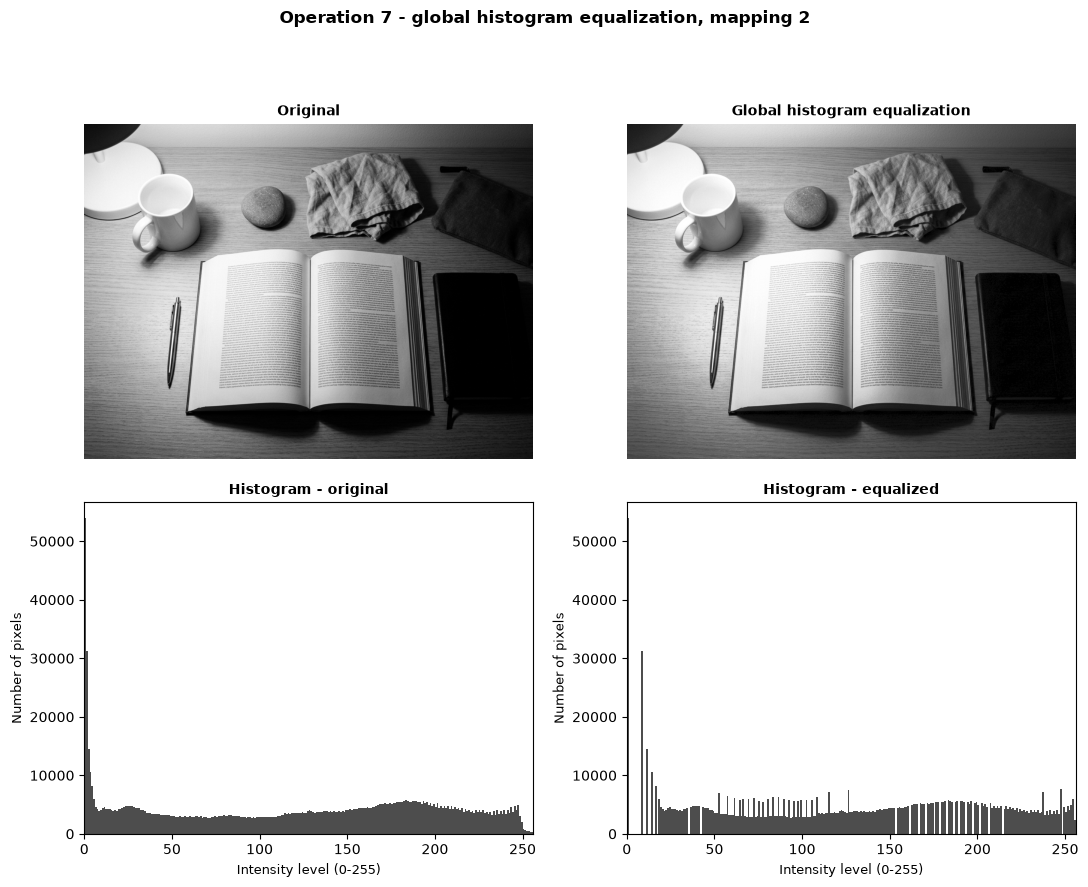

Detail and noise indicators
+-----------+---------+----------------+---------------+--------------------------+
|   Image   | Std-dev | Entropy (bits) | Edge strength | Fine-grain / noise level |
+-----------+---------+----------------+---------------+--------------------------+
|  Original |  79.27  |      7.76      |     53.90     |           7.66           |
| Equalized |  76.84  |      7.61      |     55.50     |           7.74           |
+-----------+---------+----------------+---------------+--------------------------+
+-----------+--------+---------+-----+-----+--------+----------+
|   Image   |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+-----------+--------+---------+-----+-----+--------+----------+
|  Original | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
| Equalized | 121.73 |  76.84  |  0  | 255 |  5.02  |   0.21   |
+-----------+--------+---------+-----+-----+--------+----------+


In [19]:
equalized = cv2.equalizeHist(original)

fig, axes = plt.subplots(2, 2, figsize=(11, 9), gridspec_kw={"height_ratios": [1.25, 1]})
for ax, img, title in zip(axes[0], [original, equalized], ["Original", "Global histogram equalization"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
draw_histogram(axes[1][0], original,  "Histogram - original")
draw_histogram(axes[1][1], equalized, "Histogram - equalized")
fig.suptitle("Operation 7 - global histogram equalization, mapping 2", fontsize=12, fontweight="bold")
finish_figure(fig, "op7_equalization")

m_orig = detail_metrics(original)
m_eq   = detail_metrics(equalized)
show_table(["Image", "Std-dev", "Entropy (bits)", "Edge strength", "Fine-grain / noise level"],
            [["Original"] + [f"{v:.2f}" for v in m_orig], ["Equalized"] + [f"{v:.2f}" for v in m_eq]],
            "Detail and noise indicators")
show_stats([("Original", original), ("Equalized", equalized)])

Dry-run formula (mapping 2) versus cv2.equalizeHist on the image: 100.00% of the pixels identical, largest difference 0 grey level(s).
Operation 7 — computed comparison values
+----------------------+----------+-----------+
|       Measure        | Original | Equalized |
+----------------------+----------+-----------+
|   Occupied levels    |   256    |    226    |
| Edge-strength change |    —     |   +2.97%  |
|  Fine-grain measure  |   7.66   |    7.74   |
|   Fine-grain ratio   |  1.00x   |   1.01x   |
+----------------------+----------+-----------+


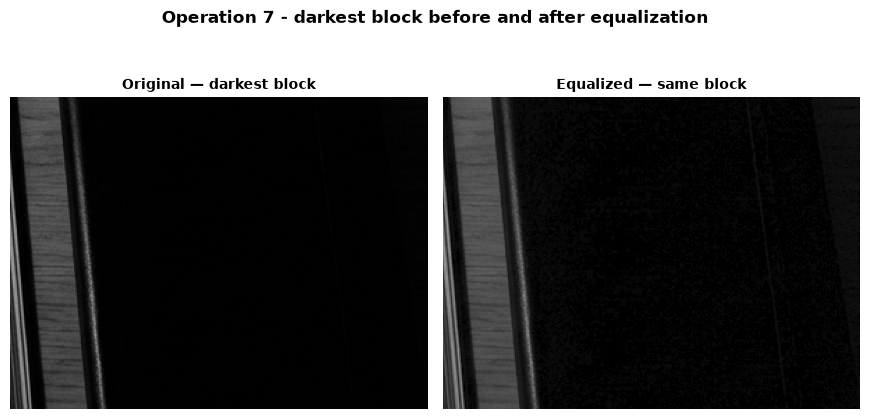

Operation 7 — local fine detail and noise proxy
+----------------------------------+----------+-----------+
| Darkest-block fine-grain measure | Original | Equalized |
+----------------------------------+----------+-----------+
|          Measured value          |   5.26   |    5.19   |
+----------------------------------+----------+-----------+


In [20]:
# does the OpenCV result agree with the dry-run formula (mapping 2) applied to the whole image?
def equalize_by_formula(img):
    n = counts256(img)
    cdf = np.cumsum(n) / img.size
    cdf_low = cdf[cdf > 0].min()
    lut = to_uint8(round_half_up(255 * (cdf - cdf_low) / (1 - cdf_low)))
    return lut[img]

by_formula = equalize_by_formula(original)
diff = np.abs(by_formula.astype(np.int16) - equalized.astype(np.int16))
print(f"Dry-run formula (mapping 2) versus cv2.equalizeHist on the image: {pct(diff == 0):.2f}% of the pixels identical, "
      f"largest difference {int(diff.max())} grey level(s).")

edge_change  = 100 * (m_eq[2] / m_orig[2] - 1)
grain_ratio  = m_eq[3] / m_orig[3]
used_before, used_after = int(np.count_nonzero(counts256(original))), int(np.count_nonzero(counts256(equalized)))
show_table(["Measure", "Original", "Equalized"],
           [["Occupied levels", f"{used_before}", f"{used_after}"],
            ["Edge-strength change", "—", f"{edge_change:+.2f}%"],
            ["Fine-grain measure", f"{m_orig[3]:.2f}", f"{m_eq[3]:.2f}"],
            ["Fine-grain ratio", "1.00x", f"{grain_ratio:.2f}x"]],
           "Operation 7 — computed comparison values")
dark_block_eq, _ = extreme_blocks(original, 4)
dark_slice_eq = block_slice(original.shape, dark_block_eq[0], dark_block_eq[1], 4)
show_gray([original[dark_slice_eq], equalized[dark_slice_eq]],
          ["Original — darkest block", "Equalized — same block"],
          "Operation 7 - darkest block before and after equalization", "op7_dark_zoom", per_row=2)
dark_fine_original = detail_metrics(original[dark_slice_eq])[3]
dark_fine_equalized = detail_metrics(equalized[dark_slice_eq])[3]
show_table(["Darkest-block fine-grain measure", "Original", "Equalized"],
           [["Measured value", f"{dark_fine_original:.2f}", f"{dark_fine_equalized:.2f}"]],
           "Operation 7 — local fine detail and noise proxy")


### Observation and verification — Global histogram equalization

- In the darkest block, edge strength rises from **20.58** to **30.36** after equalization, and the zoom shows the structure more clearly. The block's fine-grain measure changes from **5.26** to **5.19**.
- Across the whole image, the fine-grain/noise proxy changes from **7.66** to **7.74** (**1.01×**), so it does not show a clear noise increase; it combines fine detail and noise rather than measuring noise alone. A single global mapping can still make already-bright areas look washed out.
- **Verification:** the dry-run mapping 2 agrees with `cv2.equalizeHist` on **100%** of pixels, with maximum difference **0** grey levels.


---
## Operation 8 — CLAHE

Use `clipLimit = 2.0` and `tileGridSize = (8, 8)`. The grid specifies **8 × 8 tiles**, not pixels per tile. The simplified dry run uses an absolute cap of 4; that cap is not OpenCV’s `clipLimit` parameter.

### Dry run 8 — Hand calculation

Histogram: `[6, 2, 0, 0]`; total count: **8**.

**Clip counts at 4**

| Bin | Original count | Clipped count | Excess removed |
|---:|---:|---:|---:|
| 0 | 6 | 4 | 2 |
| 1 | 2 | 2 | 0 |
| 2 | 0 | 0 | 0 |
| 3 | 0 | 0 | 0 |
| **Total** | **8** | **6** | **2** |

**Redistribute the excess equally**

| Bin | Clipped count | Added `2/4` | Redistributed count |
|---:|---:|---:|---:|
| 0 | 4 | 0.5 | 4.5 |
| 1 | 2 | 0.5 | 2.5 |
| 2 | 0 | 0.5 | 0.5 |
| 3 | 0 | 0.5 | 0.5 |
| **Total** | **6** | **2** | **8** |

**Build the new CDF**

| Bin | Original CDF (no clipping) | Redistributed count | Cumulative count | New CDF |
|---:|---:|---:|---:|---:|
| 0 | 0.7500 | 4.5 | 4.5 | 0.5625 |
| 1 | 1.0000 | 2.5 | 7.0 | 0.8750 |
| 2 | 1.0000 | 0.5 | 7.5 | 0.9375 |
| 3 | 1.0000 | 0.5 | 8.0 | 1.0000 |

Clipping reduces the first CDF value from **0.75** to **0.5625**, flattening the steepest part of this mapping and limiting contrast and noise amplification.

**Why neighbouring tile mappings need interpolation**

Each tile has its own CDF, so the same intensity can map differently on opposite sides of a tile border and create a visible seam. CLAHE bilinearly blends neighboring tile mappings to soften that transition.

This hand model allows fractional redistribution and differs from OpenCV's integer redistribution. The absolute cap of 4 is not the OpenCV `clipLimit` parameter.

### Dry run 8 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [21]:
typed_histogram = [6, 2, 0, 0]
typed_clipped_histogram = [4, 2, 0, 0]
typed_redistributed_histogram = [4.5, 2.5, .5, .5]
typed_cdf_without_clipping = [.75, 1, 1, 1]
typed_cdf_after_clipping = [.5625, .875, .9375, 1]
hist_a=np.array(typed_histogram,dtype=np.float64); cap=4
clipped=np.minimum(hist_a,cap); excess=hist_a.sum()-clipped.sum()
redistributed=clipped+excess/hist_a.size
cdf_new=np.cumsum(redistributed)/redistributed.sum(); cdf_old=np.cumsum(hist_a)/hist_a.sum()
show_table(["Bin","Original count","Clipped count","Excess removed"],
           [[i,int(h),int(c),int(h-c)] for i,(h,c) in enumerate(zip(hist_a,clipped))],
           "Python dry run 8 — clip counts at 4")
show_table(["Bin","Clipped count","Added excess / 4","Redistributed count"],
           [[i,f"{c:.1f}",f"{excess/hist_a.size:.1f}",f"{r:.1f}"] for i,(c,r) in enumerate(zip(clipped,redistributed))],
           "Python dry run 8 — redistribute excess")
show_table(["Bin", "Original CDF (no clipping)", "Redistributed count", "Cumulative count", "New CDF"],
           [[i, f"{cdf_old[i]:.4f}", f"{r:.4f}", f"{np.cumsum(redistributed)[i]:.4f}", f"{cdf_new[i]:.4f}"]
            for i, r in enumerate(redistributed)],
           "Python dry run 8 — original and clipped/redistributed CDF")
assert clipped.tolist()==typed_clipped_histogram and excess==2
assert np.allclose(redistributed,typed_redistributed_histogram) and redistributed.sum()==8
assert np.allclose(cdf_old,typed_cdf_without_clipping) and np.allclose(cdf_new,typed_cdf_after_clipping)
print("✓ MATCH — clipping, redistribution, and CDF tables match the hand calculation")

Python dry run 8 — clip counts at 4
+-----+----------------+---------------+----------------+
| Bin | Original count | Clipped count | Excess removed |
+-----+----------------+---------------+----------------+
|  0  |       6        |       4       |       2        |
|  1  |       2        |       2       |       0        |
|  2  |       0        |       0       |       0        |
|  3  |       0        |       0       |       0        |
+-----+----------------+---------------+----------------+
Python dry run 8 — redistribute excess
+-----+---------------+------------------+---------------------+
| Bin | Clipped count | Added excess / 4 | Redistributed count |
+-----+---------------+------------------+---------------------+
|  0  |      4.0      |       0.5        |         4.5         |
|  1  |      2.0      |       0.5        |         2.5         |
|  2  |      0.0      |       0.5        |         0.5         |
|  3  |      0.0      |       0.5        |         0.5         |
+-----

### Image task 8 — CLAHE versus global equalization

tileGridSize = (8, 8) -> 64 tiles; each tile is about 150 x 112 pixels (16800 pixels) for this 1200 x 896 image.
clipLimit = 2.0 is a multiple of the average bin count; the corresponding absolute cap here is about 2.0 x 16800 / 256 = 131 pixels per bin per tile (not the cap of 4 used in the dry run).


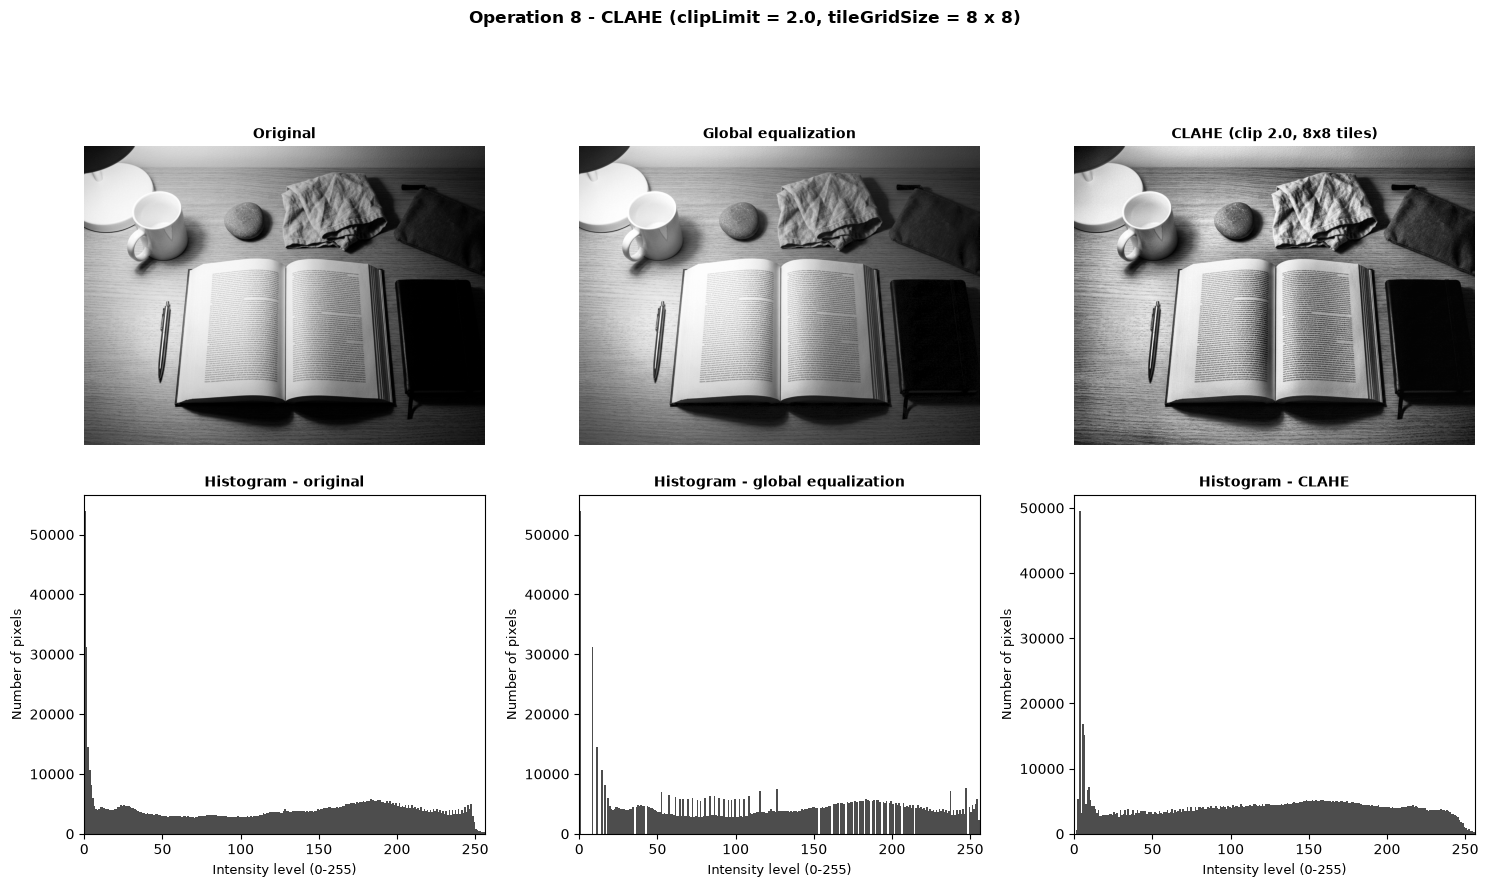

In [22]:
clip_limit, tile_grid = 2.0, (8, 8)
clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
clahe_img = clahe.apply(original)

tile_w, tile_h = -(-width // tile_grid[0]), -(-height // tile_grid[1])        # ceil division
opencv_cap = max(int(clip_limit * tile_w * tile_h / 256), 1)
print(f"tileGridSize = {tile_grid} -> {tile_grid[0] * tile_grid[1]} tiles; each tile is about {tile_w} x {tile_h} pixels "
      f"({tile_w * tile_h} pixels) for this {width} x {height} image.")
print(f"clipLimit = {clip_limit} is a multiple of the average bin count; the corresponding absolute cap here is about "
      f"{clip_limit} x {tile_w * tile_h} / 256 = {opencv_cap} pixels per bin per tile (not the cap of 4 used in the dry run).")

fig, axes = plt.subplots(2, 3, figsize=(15, 9), gridspec_kw={"height_ratios": [1.25, 1]})
for ax, img, title in zip(axes[0], [original, equalized, clahe_img],
                          ["Original", "Global equalization", "CLAHE (clip 2.0, 8x8 tiles)"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
for ax, img, title in zip(axes[1], [original, equalized, clahe_img],
                          ["Histogram - original", "Histogram - global equalization", "Histogram - CLAHE"]):
    draw_histogram(ax, img, title)
fig.suptitle("Operation 8 - CLAHE (clipLimit = 2.0, tileGridSize = 8 x 8)", fontsize=12, fontweight="bold")
finish_figure(fig, "op8_clahe")

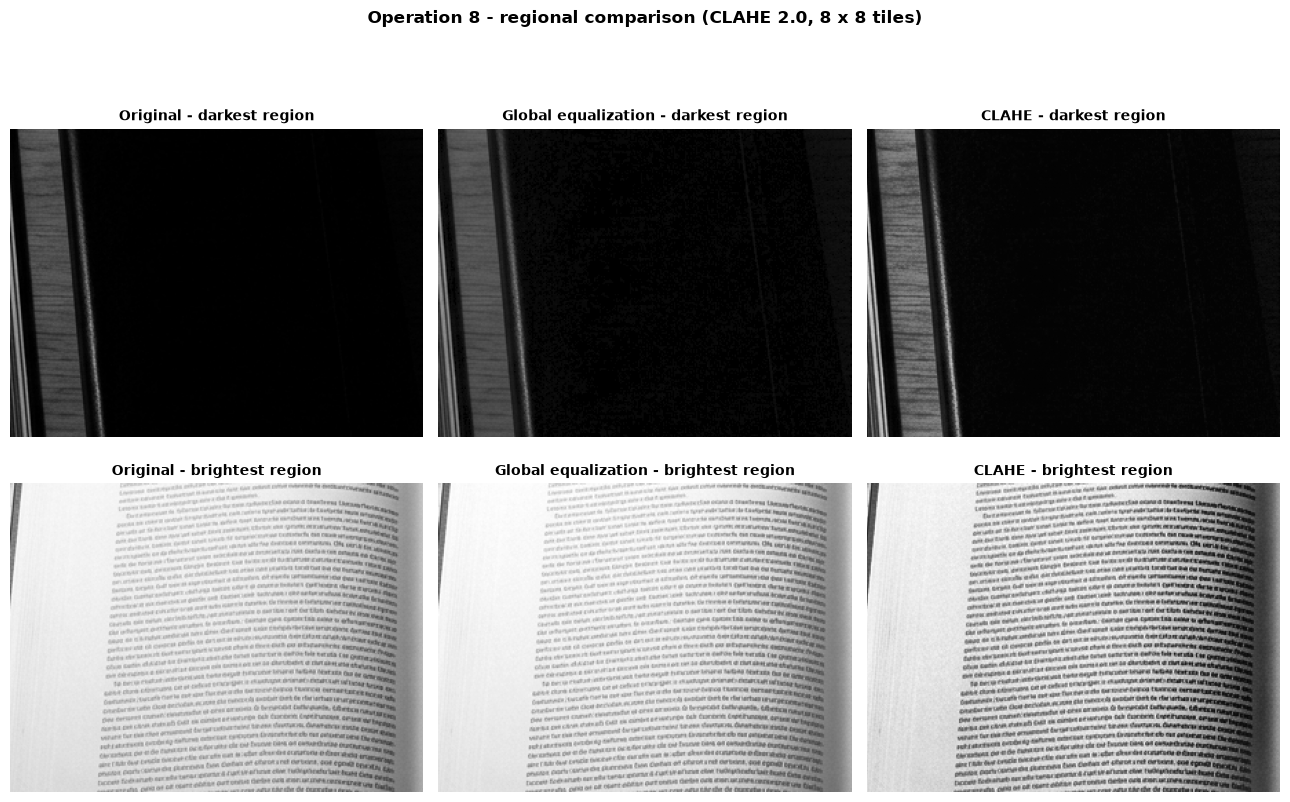

+--------------------------+---------------------+--------+---------+---------------+
| Region (of the original) |        Method       |  Mean  | Std-dev | Edge strength |
+--------------------------+---------------------+--------+---------+---------------+
|      darkest region      |       Original      | 11.16  |  26.32  |     20.58     |
|      darkest region      | Global equalization | 15.50  |  27.06  |     30.36     |
|      darkest region      |        CLAHE        | 18.82  |  35.23  |     32.96     |
|     brightest region     |       Original      | 202.14 |  38.39  |     100.27    |
|     brightest region     | Global equalization | 204.98 |  42.85  |     110.92    |
|     brightest region     |        CLAHE        | 173.65 |  64.44  |     186.22    |
+--------------------------+---------------------+--------+---------+---------------+
Detail and noise indicators
+---------------------+---------+----------------+---------------+--------------------------+
|        Image    

In [23]:
# Uneven lighting: compare the darkest and the brightest region of the ORIGINAL (4 x 4 grid of blocks)
dark_blk, bright_blk = extreme_blocks(original, 4)
candidates = [("Original", original), ("Global equalization", equalized), ("CLAHE", clahe_img)]

fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
rows, region_edge = [], {}
for r, (label, blk) in enumerate([("darkest region", dark_blk), ("brightest region", bright_blk)]):
    sl = block_slice(original.shape, blk[0], blk[1], 4)
    for c, (name, img) in enumerate(candidates):
        crop = img[sl]
        region_edge[(label, name)] = detail_metrics(crop)[2]
        axes[r, c].imshow(crop, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{name} - {label}")
        axes[r, c].axis("off")
        rows.append([label, name, f"{crop.mean():.2f}", f"{crop.std():.2f}", f"{region_edge[(label, name)]:.2f}"])
fig.suptitle("Operation 8 - regional comparison (CLAHE 2.0, 8 x 8 tiles)", fontsize=12, fontweight="bold")
finish_figure(fig, "op8_regions")
show_table(["Region (of the original)", "Method", "Mean", "Std-dev", "Edge strength"], rows)

m_cl = detail_metrics(clahe_img)
show_table(["Image", "Std-dev", "Entropy (bits)", "Edge strength", "Fine-grain / noise level"],
            [["Original"] + [f"{v:.2f}" for v in m_orig], ["Global equalization"] + [f"{v:.2f}" for v in m_eq],
             ["CLAHE"] + [f"{v:.2f}" for v in m_cl]], "Detail and noise indicators")

### Observation and interpretation — CLAHE comparison

- In the darkest block, mean/std-dev change from **11.16/26.32** (original) to **15.50/27.06** (global equalization) and **18.82/35.23** (CLAHE). In the brightest block they change from **202.14/38.39** to **204.98/42.85** and **173.65/64.44**. CLAHE lifts the dark block and pulls down the bright block while expanding each block's local spread, so it handles this image's uneven lighting better than the one global mapping.
- Edge strength also rises in both selected blocks under CLAHE. The cost is stronger fine grain: the measured fine-grain/noise indicator rises from **7.66** (original) and **7.74** (global) to **12.62** (CLAHE); this indicator combines noise and fine detail.
- `(8, 8)` means an **8 × 8 grid = 64 tiles**, not 8 × 8 pixels per tile. Each tile has its own CDF, so the same input intensity can map to different values on opposite sides of a tile border; CLAHE bilinearly interpolates neighboring tile mappings to soften seams.


---
## Operation 9 — Fixed binary thresholding

**Rule:** output 255 when `r > T`; otherwise output 0. A pixel equal to the threshold is black.

### Dry run 9 — Hand calculation

Pixels: `[0, 80, 127, 128, 180, 255]`.

**Threshold `T = 127`**

| Input `r` | `r > 127`? | Output |
|---:|:---:|---:|
| 0 | No | 0 |
| 80 | No | 0 |
| 127 | No | 0 |
| 128 | Yes | 255 |
| 180 | Yes | 255 |
| 255 | Yes | 255 |

White-pixel count: **3**.

**Threshold `T = 180`**

| Input `r` | `r > 180`? | Output |
|---:|:---:|---:|
| 0 | No | 0 |
| 80 | No | 0 |
| 127 | No | 0 |
| 128 | No | 0 |
| 180 | No | 0 |
| 255 | Yes | 255 |

White-pixel count: **1**.
The count falls from **3** white pixels at `T = 127` (128, 180, 255) to **1** at `T = 180` (255); raising `T` yields fewer white pixels, and a pixel equal to `T` stays 0 because the rule is strict `r > T`.


### Dry run 9 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [24]:
typed_threshold_pixels = [0, 80, 127, 128, 180, 255]
typed_threshold_127 = [0, 0, 0, 255, 255, 255]
typed_threshold_180 = [0, 0, 0, 0, 0, 255]
tpx=np.array(typed_threshold_pixels,dtype=np.uint8)
def rule_threshold(values,t): return np.where(np.asarray(values).astype(np.int16)>t,255,0).astype(np.uint8)
out_127,out_180=rule_threshold(tpx,127),rule_threshold(tpx,180)
show_table(["Input r","r > 127?","Output"],[[int(r),"Yes" if r>127 else "No",int(v)] for r,v in zip(tpx,out_127)],"Python dry run 9 — threshold T = 127")
show_table(["Input r","r > 180?","Output"],[[int(r),"Yes" if r>180 else "No",int(v)] for r,v in zip(tpx,out_180)],"Python dry run 9 — threshold T = 180")
assert out_127.tolist()==typed_threshold_127 and out_180.tolist()==typed_threshold_180
assert np.count_nonzero(out_127==255)==3 and np.count_nonzero(out_180==255)==1
cv_127=cv2.threshold(tpx.reshape(1,-1),127,255,cv2.THRESH_BINARY)[1].ravel()
cv_180=cv2.threshold(tpx.reshape(1,-1),180,255,cv2.THRESH_BINARY)[1].ravel()
assert np.array_equal(cv_127,out_127) and np.array_equal(cv_180,out_180)
print("✓ MATCH — both Python tables match the hand calculation")
print("✓ MATCH — OpenCV binary threshold matches both predicted outputs")

Python dry run 9 — threshold T = 127
+---------+----------+--------+
| Input r | r > 127? | Output |
+---------+----------+--------+
|    0    |    No    |   0    |
|    80   |    No    |   0    |
|   127   |    No    |   0    |
|   128   |   Yes    |  255   |
|   180   |   Yes    |  255   |
|   255   |   Yes    |  255   |
+---------+----------+--------+
Python dry run 9 — threshold T = 180
+---------+----------+--------+
| Input r | r > 180? | Output |
+---------+----------+--------+
|    0    |    No    |   0    |
|    80   |    No    |   0    |
|   127   |    No    |   0    |
|   128   |    No    |   0    |
|   180   |    No    |   0    |
|   255   |   Yes    |  255   |
+---------+----------+--------+
✓ MATCH — both Python tables match the hand calculation
✓ MATCH — OpenCV binary threshold matches both predicted outputs


### Image task 9 — Fixed threshold at T = 127

cv2.threshold result equals the rule 'r > T -> 255, else 0': True
Unique values in the binary image: [0, 255]
White pixels: 49.98%   Black pixels: 50.02%


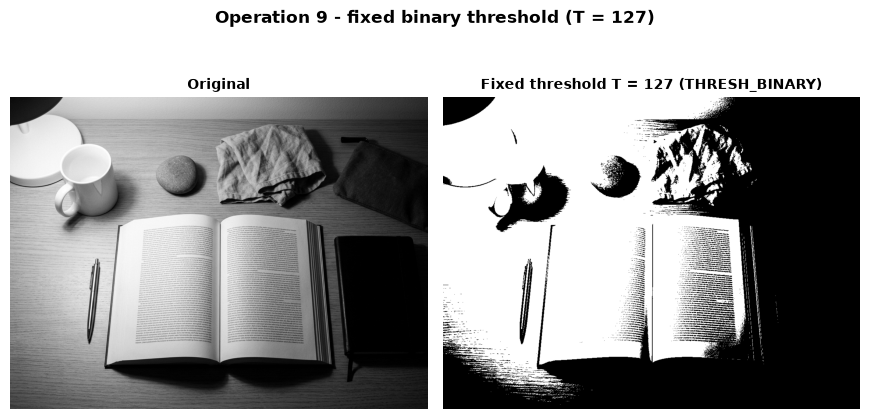

In [25]:
T_fixed = 127
_, fixed_mask = cv2.threshold(original, T_fixed, 255, cv2.THRESH_BINARY)

assert np.array_equal(fixed_mask, rule_threshold(original, T_fixed))
print("cv2.threshold result equals the rule 'r > T -> 255, else 0':", True)
print("Unique values in the binary image:", np.unique(fixed_mask).tolist())
print(f"White pixels: {pct(fixed_mask == 255):.2f}%   Black pixels: {pct(fixed_mask == 0):.2f}%")

show_gray([original, fixed_mask], ["Original", f"Fixed threshold T = {T_fixed} (THRESH_BINARY)"],
          "Operation 9 - fixed binary threshold (T = 127)", "op9_fixed_threshold")

### Observation and verification — Fixed threshold

- At `T = 127`, the binary output contains only **0** and **255**; **49.98%** are white and **50.02%** black.
- **Verification:** the code check confirms `r > T → 255`; a pixel equal to the threshold remains black. A global threshold can misclassify areas under uneven illumination.


---
## Operation 10 — Otsu thresholding

Otsu selects the threshold that maximizes `w0 × w1 × (μ0 − μ1)²`, where the classes are `r ≤ T` and `r > T`.

### Dry run 10 — Hand calculation

Pixels: `[0, 1, 4, 5]`. For every candidate `T`, calculate each class’s weight and mean.

| `T` | Class 0 | Class 1 | `w0` | `w1` | `μ0` | `μ1` | Between-class variance |
|---:|---|---|---:|---:|---:|---:|---:|
| 0 | {0} | {1, 4, 5} | 0.25 | 0.75 | 0 | 3.333 | 2.0833 |
| 1 | {0, 1} | {4, 5} | 0.50 | 0.50 | 0.5 | 4.5 | 4.0000 |
| 2 | {0, 1} | {4, 5} | 0.50 | 0.50 | 0.5 | 4.5 | 4.0000 |
| 3 | {0, 1} | {4, 5} | 0.50 | 0.50 | 0.5 | 4.5 | 4.0000 |
| 4 | {0, 1, 4} | {5} | 0.75 | 0.25 | 1.667 | 5 | 2.0833 |

The maximum ties at `T = 1, 2, 3`; choose the smallest, **T = 1**. The predicted binary mask is **[0, 0, 255, 255]**.

### Dry run 10 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [26]:
typed_otsu_pixels = [0, 1, 4, 5]
typed_otsu_scores = [25/12, 4, 4, 4, 25/12]
typed_otsu_ties = [1, 2, 3]
typed_otsu_threshold = 1
typed_otsu_mask = [0, 0, 255, 255]
opx=np.array(typed_otsu_pixels,dtype=np.uint8)
rows=[]; scores=[]
for t in range(5):
    c0,c1=opx[opx<=t].astype(float),opx[opx>t].astype(float)
    w0,w1=c0.size/opx.size,c1.size/opx.size
    m0,m1=c0.mean(),c1.mean()
    score=w0*w1*(m0-m1)**2; scores.append(score)
    rows.append([t,c0.astype(int).tolist(),c1.astype(int).tolist(),f"{w0:.2f}",f"{w1:.2f}",f"{m0:.3f}",f"{m1:.3f}",f"{score:.4f}"])
show_table(["T","Class 0 (r<=T)","Class 1 (r>T)","w0","w1","mu0","mu1","Between-class variance"],rows,"Python dry run 10 — Otsu scores")
best=max(scores); tied=[t for t,s in enumerate(scores) if np.isclose(s,best)]; T_hand=min(tied)
predicted=rule_threshold(opx,T_hand)
cv_T,cv_mask=cv2.threshold(opx.reshape(1,-1),0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
assert np.allclose(scores,typed_otsu_scores) and tied==typed_otsu_ties and T_hand==typed_otsu_threshold
assert predicted.tolist()==typed_otsu_mask and float(cv_T)==1 and np.array_equal(cv_mask.ravel(),predicted)
print("✓ MATCH — all class weights, means, and variance scores match the hand table")
print("✓ MATCH — smallest tied maximum is T = 1; predicted mask is",predicted.tolist())
print("✓ MATCH — cv2.THRESH_OTSU returns T =",cv_T,"and the same mask")

Python dry run 10 — Otsu scores
+---+----------------+---------------+------+------+-------+-------+------------------------+
| T | Class 0 (r<=T) | Class 1 (r>T) |  w0  |  w1  |  mu0  |  mu1  | Between-class variance |
+---+----------------+---------------+------+------+-------+-------+------------------------+
| 0 |      [0]       |   [1, 4, 5]   | 0.25 | 0.75 | 0.000 | 3.333 |         2.0833         |
| 1 |     [0, 1]     |     [4, 5]    | 0.50 | 0.50 | 0.500 | 4.500 |         4.0000         |
| 2 |     [0, 1]     |     [4, 5]    | 0.50 | 0.50 | 0.500 | 4.500 |         4.0000         |
| 3 |     [0, 1]     |     [4, 5]    | 0.50 | 0.50 | 0.500 | 4.500 |         4.0000         |
| 4 |   [0, 1, 4]    |      [5]      | 0.75 | 0.25 | 1.667 | 5.000 |         2.0833         |
+---+----------------+---------------+------+------+-------+-------+------------------------+
✓ MATCH — all class weights, means, and variance scores match the hand table
✓ MATCH — smallest tied maximum is T = 1; pre

### Image task 10 — Otsu versus the fixed threshold

Threshold returned by OpenCV Otsu : 110.0
Threshold from my own Otsu search  : 110   (smallest T with the maximal between-class variance)
Masks from the two thresholds identical: True
Unique values in the Otsu image: [0, 255]


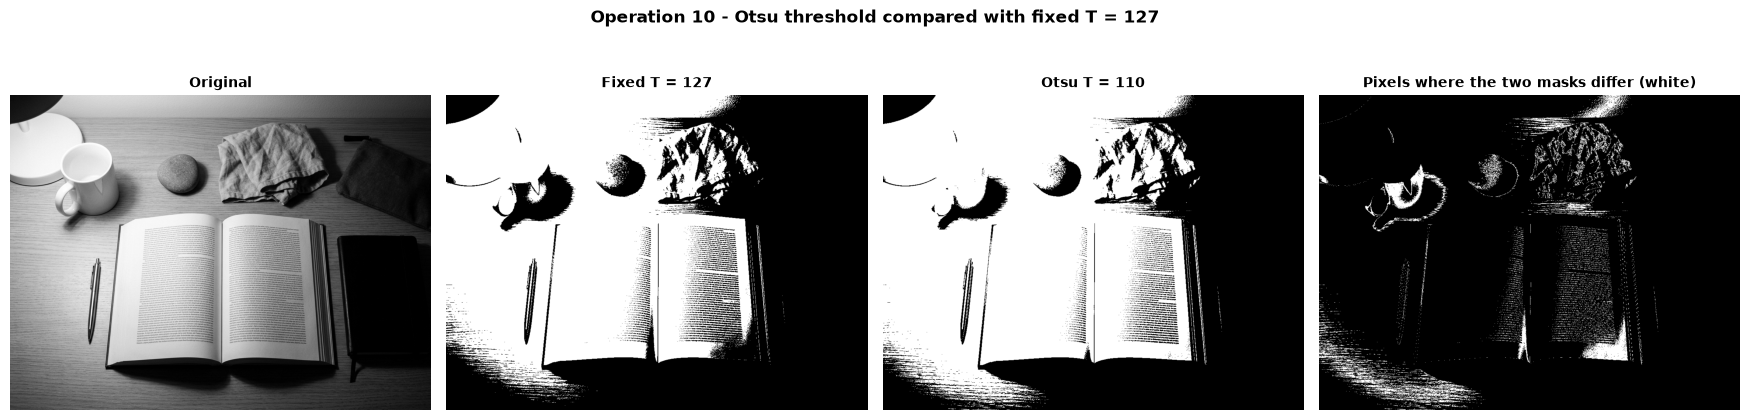

Operation 10 — fixed/Otsu mask agreement and difference range
+------------------------------+--------+
|       Mask comparison        | Value  |
+------------------------------+--------+
|          Agreement           | 94.48% |
|         Disagreement         | 5.52%  |
| Minimum differing grey level |  111   |
| Maximum differing grey level |  127   |
+------------------------------+--------+


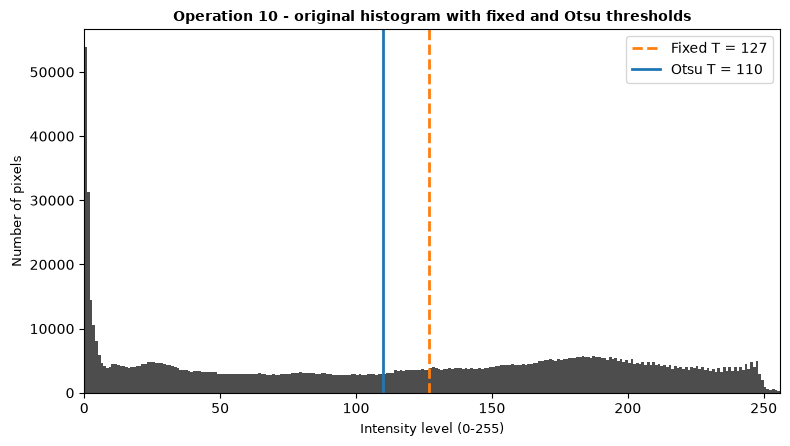

In [27]:
T_otsu, otsu_mask = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)


# independent check: the same between-class-variance rule applied to the image histogram
def otsu_scores(img):
    n = counts256(img).astype(np.float64)
    w0 = np.cumsum(n) / n.sum()
    w1 = 1.0 - w0
    cum_mean = np.cumsum(n * np.arange(256)) / n.sum()
    total_mean = cum_mean[-1]
    valid = (w0 > 0) & (w1 > 0)
    mu0 = np.zeros(256); mu1 = np.zeros(256)
    mu0[valid] = cum_mean[valid] / w0[valid]
    mu1[valid] = (total_mean - cum_mean[valid]) / w1[valid]
    s = np.full(256, -1.0)
    s[valid] = w0[valid] * w1[valid] * (mu0[valid] - mu1[valid]) ** 2
    return s

assert np.allclose(otsu_scores(opx)[:5], scores)            # same function reproduces the dry run
img_scores = otsu_scores(original)
my_T = int(np.flatnonzero(img_scores >= img_scores.max() - 1e-9 * img_scores.max())[0])
print(f"Threshold returned by OpenCV Otsu : {T_otsu}")
print(f"Threshold from my own Otsu search  : {my_T}   (smallest T with the maximal between-class variance)")
print(f"Masks from the two thresholds identical: {np.array_equal(otsu_mask, rule_threshold(original, my_T))}")
print("Unique values in the Otsu image:", np.unique(otsu_mask).tolist())

disagree = np.where(fixed_mask != otsu_mask, 255, 0).astype(np.uint8)
show_gray([original, fixed_mask, otsu_mask, disagree],
          ["Original", f"Fixed T = {T_fixed}", f"Otsu T = {T_otsu:.0f}", "Pixels where the two masks differ (white)"],
          "Operation 10 - Otsu threshold compared with fixed T = 127", "op10_otsu", per_row=4)
different_levels = original[fixed_mask != otsu_mask]
assert different_levels.size > 0
show_table(["Mask comparison", "Value"],
           [["Agreement", f"{pct(fixed_mask == otsu_mask):.2f}%"],
            ["Disagreement", f"{pct(fixed_mask != otsu_mask):.2f}%"],
            ["Minimum differing grey level", f"{int(different_levels.min())}"],
            ["Maximum differing grey level", f"{int(different_levels.max())}"]],
           "Operation 10 — fixed/Otsu mask agreement and difference range")
fig, ax = plt.subplots(figsize=(8, 4.8))
draw_histogram(ax, original, "Operation 10 - original histogram with fixed and Otsu thresholds")
ax.axvline(T_fixed, color="tab:orange", linestyle="--", linewidth=2, label=f"Fixed T = {T_fixed}")
ax.axvline(T_otsu, color="tab:blue", linestyle="-", linewidth=2, label=f"Otsu T = {T_otsu:.0f}")
ax.legend()
finish_figure(fig, "op10_threshold_histogram")


### Observation and interpretation — Otsu thresholding

- Otsu chooses **T = 110** versus fixed **127**. White-pixel shares are **55.50%** and **49.98%**.
- The masks agree on **94.48%** and differ on **5.52%** of pixels, at levels **111–127**.
- **Verification:** independent between-class-variance search also gives 110 and reproduces OpenCV's mask. Otsu adapts to the histogram but remains a global threshold.


---
## Operation 11 — Adaptive Gaussian thresholding

Each pixel uses a Gaussian-weighted local mean minus `C`. The image task uses `blockSize = 11` and `C = 2`.

### Dry run 11 — Hand calculation

Neighborhood:

```text
[[100, 100, 100],
 [100, 120, 140],
 [140, 140, 140]]
```

Gaussian weights are `[[1,2,1],[2,4,2],[1,2,1]] / 16`.

**Weighted mean**

| Row | Weighted products | Row sum |
|---:|---|---:|
| 1 | `1×100 + 2×100 + 1×100` | 400 |
| 2 | `2×100 + 4×120 + 2×140` | 960 |
| 3 | `1×140 + 2×140 + 1×140` | 560 |
| **Total** | **1920 / 16** | **Mean = 120** |

Threshold: `T = 120 − 2 = 118`.

**Classify the center and an equality case**

| Pixel value | Comparison | Output |
|---:|---|---:|
| 120 | `120 > 118` | 255 |
| 118 | `118 > 118` is false | 0 |

The equality case confirms the strict `>` rule. The Python verification also applies OpenCV’s Gaussian adaptive threshold to both 3 × 3 patches and asserts the center outputs. This dry run uses 3 × 3 weights; the image task uses 11 × 11.

### Dry run 11 — Python verification

The next cell recomputes the hand calculation and checks the expected values.

In [28]:
typed_neighborhood = [[100,100,100],[100,120,140],[140,140,140]]
typed_row_sums = [400, 960, 560]
typed_weighted_mean = 120
typed_threshold = 118
typed_center_outputs = [255, 0]
N=np.array(typed_neighborhood,dtype=np.float64)
W=np.array([[1,2,1],[2,4,2],[1,2,1]],dtype=np.float64)/16
row_sums=(N*W*16).sum(axis=1); weighted_mean=float((N*W).sum()); C=2; T_local=weighted_mean-C
centre=int(N[1,1])
show_table(["Row","Weighted products","Row sum"],
           [[1,"1x100 + 2x100 + 1x100",int(row_sums[0])],
            [2,"2x100 + 4x120 + 2x140",int(row_sums[1])],
            [3,"1x140 + 2x140 + 1x140",int(row_sums[2])],
            ["Total","1920 / 16","Mean = 120"]],
           "Python dry run 11 — Gaussian-weighted mean")
show_table(["Pixel value","Threshold","Decision","Output"],
           [[120,118,"120 > 118",255],[118,118,"118 > 118 is false",0]],
           "Python dry run 11 — classify center and equality case")
assert row_sums.tolist()==typed_row_sums and W.sum()==1 and weighted_mean==typed_weighted_mean and T_local==typed_threshold
assert [(255 if centre>T_local else 0),(255 if 118>T_local else 0)]==typed_center_outputs
print("✓ MATCH — weighted mean and both classifications match the hand tables")


# Verify the same two center decisions with OpenCV's 3 x 3 adaptive Gaussian method.
patch = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=np.uint8)
equality_patch = np.array([[100, 100, 100], [100, 118, 140], [140, 140, 148]], dtype=np.uint8)
patch_mask = cv2.adaptiveThreshold(patch, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, 3, 2)
equality_mask = cv2.adaptiveThreshold(equality_patch, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv2.THRESH_BINARY, 3, 2)
assert int(patch_mask[1, 1]) == 255 and int(equality_mask[1, 1]) == 0
print("✓ MATCH — OpenCV 3 x 3 center outputs are 255 for 120 > 118 and 0 for 118 = 118")


Python dry run 11 — Gaussian-weighted mean
+-------+-----------------------+------------+
|  Row  |   Weighted products   |  Row sum   |
+-------+-----------------------+------------+
|   1   | 1x100 + 2x100 + 1x100 |    400     |
|   2   | 2x100 + 4x120 + 2x140 |    960     |
|   3   | 1x140 + 2x140 + 1x140 |    560     |
| Total |       1920 / 16       | Mean = 120 |
+-------+-----------------------+------------+
Python dry run 11 — classify center and equality case
+-------------+-----------+--------------------+--------+
| Pixel value | Threshold |      Decision      | Output |
+-------------+-----------+--------------------+--------+
|     120     |    118    |     120 > 118      |  255   |
|     118     |    118    | 118 > 118 is false |   0    |
+-------------+-----------+--------------------+--------+
✓ MATCH — weighted mean and both classifications match the hand tables
✓ MATCH — OpenCV 3 x 3 center outputs are 255 for 120 > 118 and 0 for 118 = 118


### Image task 11 — Adaptive Gaussian thresholding

The result includes a focused comparison of the darkest and brightest image regions. `blockSize = 11` is an 11 × 11 pixel window, and `C = 2` is subtracted from each Gaussian-weighted local mean.

Adaptive Gaussian parameters: blockSize = 11 (11 x 11), C = 2
Unique values in the adaptive image: [0, 255]


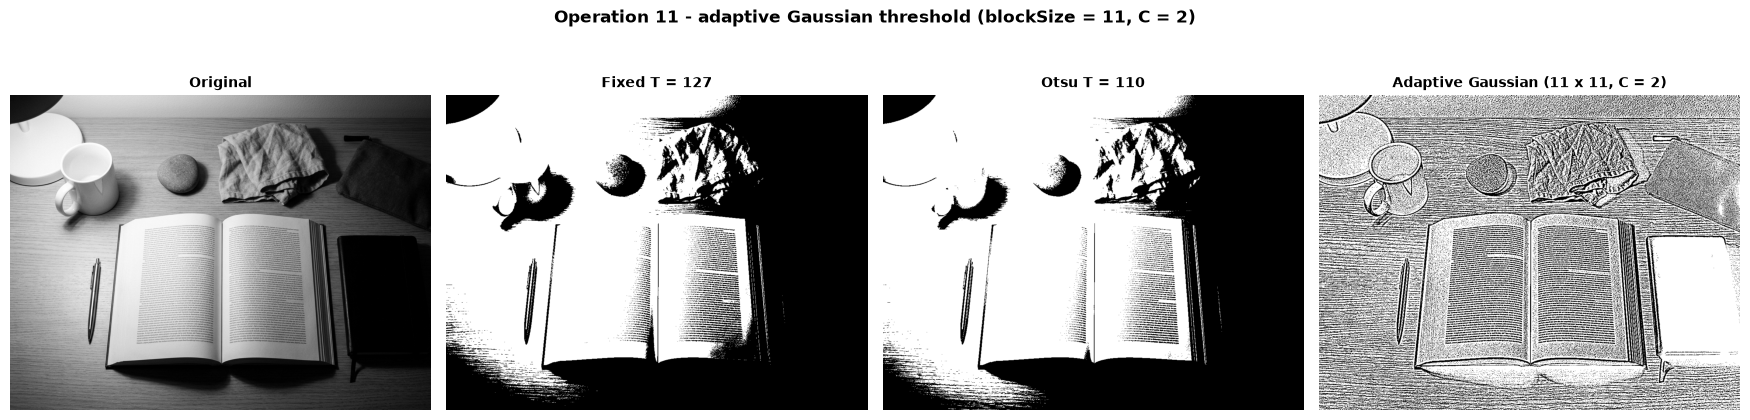

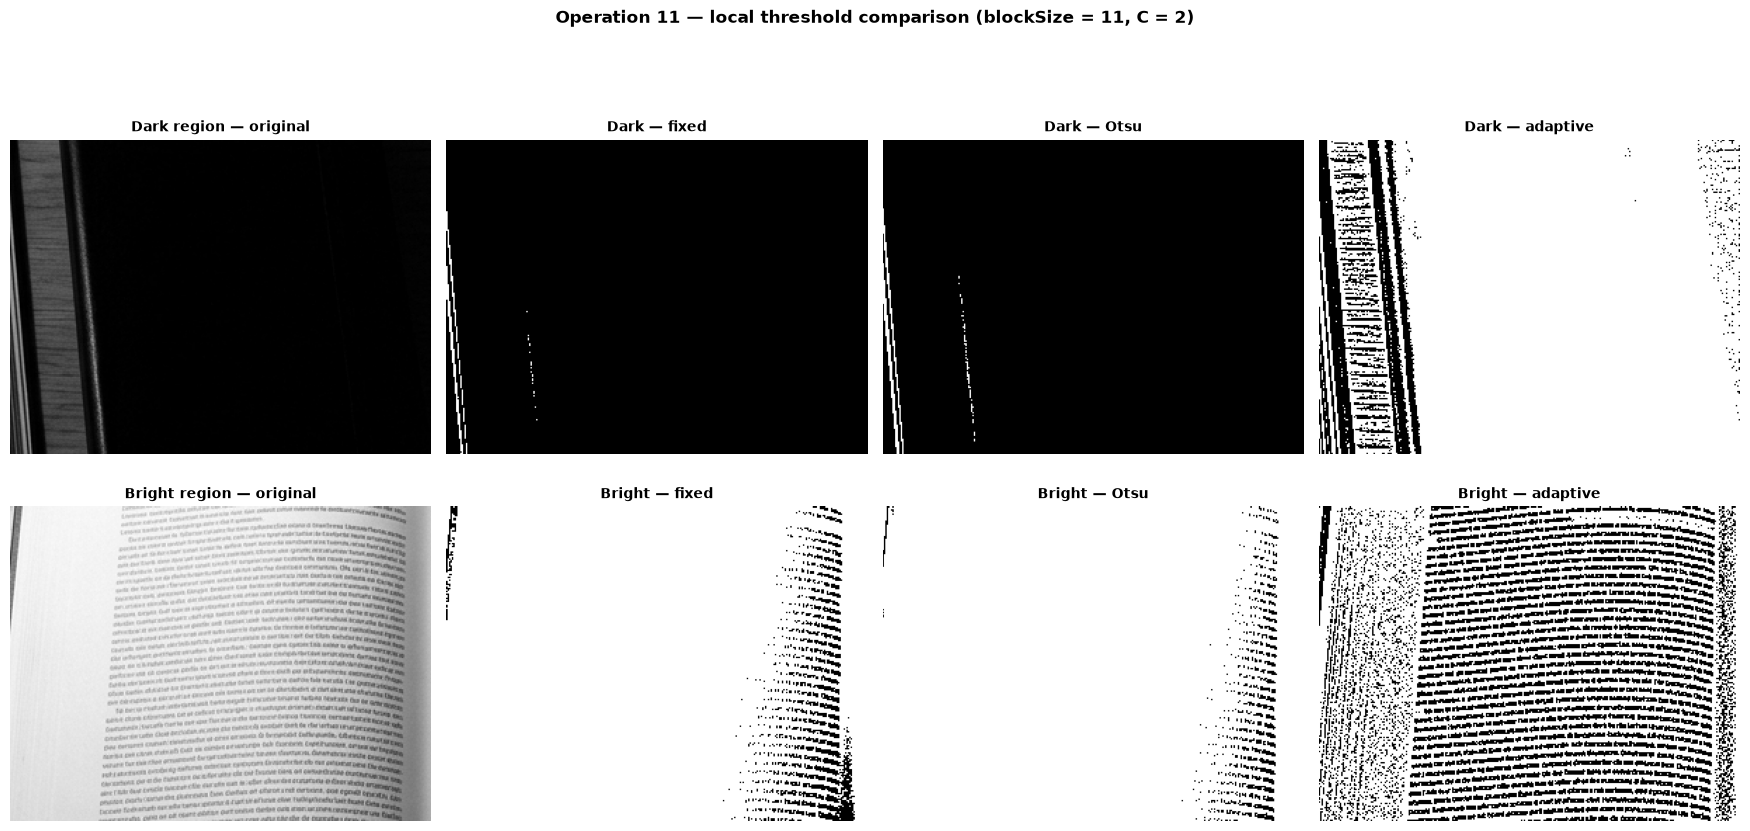

Global versus local thresholds
+-------------------+----------------+------------------+
|       Method      |   Threshold    | White pixels (%) |
+-------------------+----------------+------------------+
|       Fixed       |      127       |      49.98       |
|        Otsu       |      110       |      55.50       |
| Adaptive Gaussian | local mean - 2 |      67.71       |
+-------------------+----------------+------------------+
+-------------------+---------------+
|   Pair of masks   | Agreement (%) |
+-------------------+---------------+
|   Fixed vs Otsu   |     94.48     |
| Fixed vs Adaptive |     54.19     |
|  Otsu vs Adaptive |     54.92     |
+-------------------+---------------+


In [29]:
print("Adaptive Gaussian parameters: blockSize = 11 (11 x 11), C = 2")
adaptive_mask = cv2.adaptiveThreshold(original, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv2.THRESH_BINARY, 11, 2)
print("Unique values in the adaptive image:", np.unique(adaptive_mask).tolist())

show_gray([original, fixed_mask, otsu_mask, adaptive_mask],
          ["Original", f"Fixed T = {T_fixed}", f"Otsu T = {T_otsu:.0f}", "Adaptive Gaussian (11 x 11, C = 2)"],
          "Operation 11 - adaptive Gaussian threshold (blockSize = 11, C = 2)", "op11_adaptive", per_row=4)

# Compare local details in one dark and one bright region under the same three masks.
dark_blk, bright_blk = extreme_blocks(original, 4)
dark_slice = block_slice(original.shape, dark_blk[0], dark_blk[1], 4)
bright_slice = block_slice(original.shape, bright_blk[0], bright_blk[1], 4)
show_gray([original[dark_slice], fixed_mask[dark_slice], otsu_mask[dark_slice], adaptive_mask[dark_slice],
           original[bright_slice], fixed_mask[bright_slice], otsu_mask[bright_slice], adaptive_mask[bright_slice]],
          ["Dark region — original", "Dark — fixed", "Dark — Otsu", "Dark — adaptive",
           "Bright region — original", "Bright — fixed", "Bright — Otsu", "Bright — adaptive"],
          "Operation 11 — local threshold comparison (blockSize = 11, C = 2)", "op11_local_regions", per_row=4)

masks = [("Fixed", fixed_mask), ("Otsu", otsu_mask), ("Adaptive", adaptive_mask)]
show_table(["Method", "Threshold", "White pixels (%)"],
            [["Fixed", T_fixed, f"{pct(fixed_mask == 255):.2f}"],
             ["Otsu", f"{T_otsu:.0f}", f"{pct(otsu_mask == 255):.2f}"],
             ["Adaptive Gaussian", "local mean - 2", f"{pct(adaptive_mask == 255):.2f}"]], "Global versus local thresholds")
show_table(["Pair of masks", "Agreement (%)"],
            [["Fixed vs Otsu", f"{pct(fixed_mask == otsu_mask):.2f}"],
             ["Fixed vs Adaptive", f"{pct(fixed_mask == adaptive_mask):.2f}"],
             ["Otsu vs Adaptive", f"{pct(otsu_mask == adaptive_mask):.2f}"]])

In [30]:
# Uneven lighting probe: percentage of white pixels inside the darkest and brightest region of the original
dark_blk, bright_blk = extreme_blocks(original, 4)
rows = []
for label, blk in (("darkest region", dark_blk), ("brightest region", bright_blk)):
    sl = block_slice(original.shape, blk[0], blk[1], 4)
    rows.append([label, f"{original[sl].mean():.1f}"] + [f"{pct(m[sl] == 255):.1f}" for _, m in masks])
show_table(["Region of the original", "Mean level", "% white: Fixed", "% white: Otsu", "% white: Adaptive"], rows)


+------------------------+------------+----------------+---------------+-------------------+
| Region of the original | Mean level | % white: Fixed | % white: Otsu | % white: Adaptive |
+------------------------+------------+----------------+---------------+-------------------+
|     darkest region     |    11.2    |      0.7       |      0.9      |        88.4       |
|    brightest region    |   202.1    |      95.0      |      97.6     |        65.0       |
+------------------------+------------+----------------+---------------+-------------------+


### Observation and interpretation — Adaptive Gaussian thresholding

- In the darkest/brightest blocks, fixed threshold makes **0.7%/95.0%** white; Otsu makes **0.9%/97.6%**. Adaptive thresholding gives **88.4%/65.0%** white in those same blocks, showing its response to local neighborhoods.
- The image task's `blockSize = 11` means an **11 × 11 pixel window**, with `C = 2`. A local threshold can help with a document photo that has shadows or uneven lighting; flat areas may turn white and fine speckle may appear, so the result can behave more like an edge/local-contrast map than a clean region mask.
- A global threshold is often better when lighting is uniform and foreground/background intensities have a clear gap.


---
## Transfer curves — summary figure

The plot below compares the intensity mappings used in this lab and complements the image comparisons.

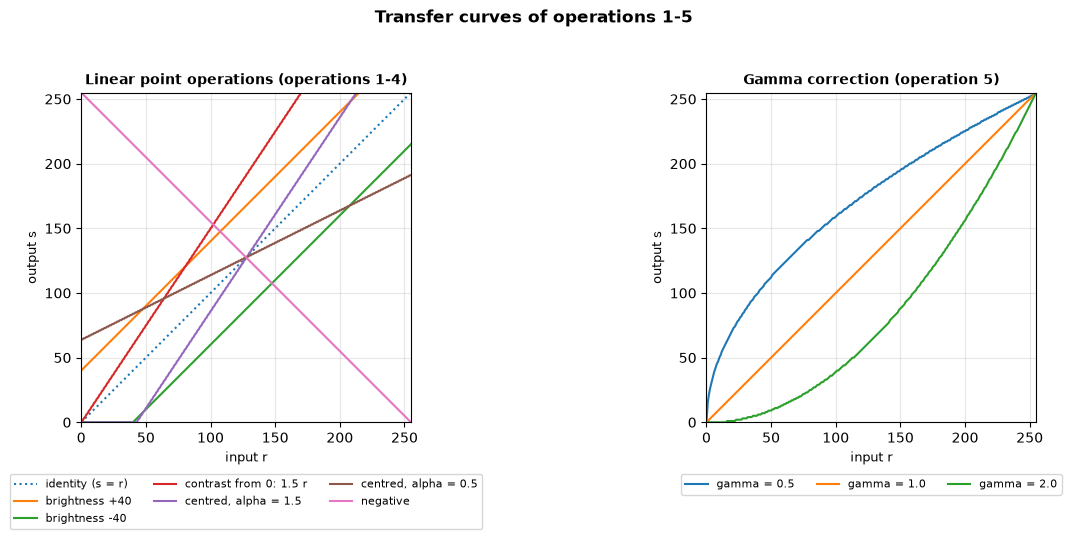

All enhanced images at a glance
+---------------------+--------+---------+-----+-----+--------+----------+
|        Image        |  Mean  | Std-dev | Min | Max | % at 0 | % at 255 |
+---------------------+--------+---------+-----+-----+--------+----------+
|       Original      | 118.31 |  79.27  |  0  | 255 |  5.02  |   0.03   |
|    Brightness +40   | 156.13 |  76.20  |  40 | 255 |  0.00  |  12.64   |
|    Brightness -40   | 85.16  |  70.25  |  0  | 215 | 25.16  |   0.00   |
|    Contrast 1.5 r   | 158.78 |  97.53  |  0  | 255 |  5.02  |  33.86   |
|     Centred 1.5     | 120.89 |  98.58  |  0  | 255 | 26.09  |  13.42   |
|     Centred 0.5     | 122.91 |  39.62  |  64 | 191 |  0.00  |   0.00   |
|       Negative      | 136.69 |  79.27  |  0  | 255 |  0.03  |   5.02   |
|      Gamma 0.5      | 156.11 |  75.02  |  0  | 255 |  5.02  |   0.03   |
|      Gamma 2.0      | 79.14  |  73.90  |  0  | 255 | 15.52  |   0.03   |
| Global equalization | 121.73 |  76.84  |  0  | 255 |  5.02  |   0.

In [31]:
# Operations 1-5 — transfer curves (parameter values in legend) (computed with the same safe recipe as above)
r_axis = np.arange(256)
curves = {
    "identity (s = r)":            r_axis,
    "brightness +40":              to_uint8(r_axis.astype(np.int16) + 40),
    "brightness -40":              to_uint8(r_axis.astype(np.int16) - 40),
    "contrast from 0: 1.5 r":      to_uint8(1.5 * r_axis),
    "centred, alpha = 1.5":        to_uint8(centred_raw(r_axis, 1.5)),
    "centred, alpha = 0.5":        to_uint8(centred_raw(r_axis, 0.5)),
    "negative":                    to_uint8(255 - r_axis),
}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
for label, curve in curves.items():
    axes[0].plot(r_axis, curve, ":" if label.startswith("identity") else "-", label=label)
axes[0].set_title("Linear point operations (operations 1-4)")
for g in (0.5, 1.0, 2.0):
    axes[1].plot(r_axis, to_uint8(gamma_scaled(r_axis, g)), label=f"gamma = {g}")
axes[1].set_title("Gamma correction (operation 5)")
for ax in axes:
    ax.set_xlim(0, 255); ax.set_ylim(0, 255); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_xlabel("input r"); ax.set_ylabel("output s")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
fig.suptitle("Transfer curves of operations 1-5", fontsize=12, fontweight="bold")
finish_figure(fig, "c_transfer_curves")

show_stats([("Original", original), ("Brightness +40", brighter), ("Brightness -40", darker),
             ("Contrast 1.5 r", contrast_zero), ("Centred 1.5", centred_15), ("Centred 0.5", centred_05),
             ("Negative", negative), ("Gamma 0.5", gamma_half), ("Gamma 2.0", gamma_two),
             ("Global equalization", equalized), ("CLAHE", clahe_img)], "All enhanced images at a glance")

### Required method notes

- **Clipping and overflow.** Widen values before arithmetic, then clip to 0–255 before converting to `uint8`; clipping merges distinct out-of-range values and loses detail. In unsigned 8-bit arithmetic, `240 + 40` wraps to **24**, while the safe clipped result is **255**.
- **Brightness and contrast.** Brightness adds a constant and shifts intensity levels. Contrast scales distances between intensity levels, either from zero or around the chosen pivot 128.
- **Gamma convention.** This notebook uses `s = 255(r/255)^γ`, with both endpoints 0 and 255 fixed. Values `γ < 1` brighten dark tones, while `γ > 1` darken them.
- **Global and local methods.** Global enhancement or thresholding uses one mapping or threshold for the whole image and works well under uniform illumination. Local methods adapt to neighborhoods and help with uneven lighting, but may amplify noise or fine texture.


In [32]:
# closing checks: the original was never modified, and the figures are ready for the report
assert np.array_equal(original, cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)), "original image changed!"
print("Original image is still identical to the file on disk: True")
print(f"Student: {STUDENT_NAME} | Roll no.: {ROLL_NUMBER}")
if SAVE_FIGS:
    saved = sorted(f for f in os.listdir(FIG_DIR) if f.endswith(".png"))
    print(f"\n{len(saved)} figures saved in the folder '{FIG_DIR}/' for the report:")
    for f in saved:
        print("  -", f)

Original image is still identical to the file on disk: True
Student: Shahzad Ahmed Awan | Roll no.: 2024-SE-15

20 figures saved in the folder 'lab03_figures/' for the report:
  - a_numeric_safety.png
  - a_original.png
  - c_transfer_curves.png
  - op10_otsu.png
  - op10_threshold_histogram.png
  - op11_adaptive.png
  - op11_local_regions.png
  - op1_brightness.png
  - op2_linear_contrast.png
  - op3_centred_contrast.png
  - op4_negative.png
  - op5_gamma_curves.png
  - op5_gamma_dark_zoom.png
  - op5_gamma_images.png
  - op6_histogram.png
  - op7_dark_zoom.png
  - op7_equalization.png
  - op8_clahe.png
  - op8_regions.png
  - op9_fixed_threshold.png


## Final summary

All **11 required dry runs** include hand calculations and matching Python checks. The implementations widen arithmetic before clipping, preserve the original image, and compare each result with labeled grayscale figures. Numerical checks agree with the manual examples, including the brightness loop/vectorized comparison and histogram-equalization mapping. Results demonstrate brightness, contrast, negative, gamma, histogram, equalization, CLAHE, and global/local threshold behavior for this image. Enhancement choices remain image-dependent: clipping loses detail, global methods can miss local illumination changes, and CLAHE can amplify fine grain. Student details, input image, and figures accompany the notebook.
